# When Can Clustering Be Trusted?
## A Stability Analysis of Unsupervised Learning Under Perturbation

> **What this is and is not:** This is an empirical investigation into the reliability of clustering analyses, not a tutorial on how to cluster data. The central question: when the data-generating process departs from idealised conditions, do clustering results remain stable and meaningful?
>
> Every experiment probes a specific assumption underlying common clustering workflows. The Limitations section is explicit about what can and cannot be concluded from this analysis.

## Motivation

Unsupervised clustering is widely used to discover structure in data, particularly in high-dimensional domains like genomics and immunology. Clustering conclusions rest on assumptions that are rarely made explicit:

1. That the chosen distance metric captures meaningful similarity
2. That the number of clusters k reflects real structure, not algorithmic artefact
3. That preprocessing choices (scaling, dimensionality reduction) are neutral
4. That results are stable, meaning they would re-emerge with slightly different data

This notebook tests these assumptions using controlled perturbation experiments on three datasets: two sklearn benchmarks with independent ground truth labels, and one real single-cell RNA-seq dataset (PBMC 3k) where the "ground truth" is itself clustering-derived. This difference in ground truth quality is a key part of what the analysis reveals.

## Key Methodological Decisions

This analysis rests on several non-obvious choices. They are listed here upfront so that a reader who disagrees with any of them can identify exactly which results are affected.

---

### Decision 1: n_iterations=50 for bootstrap stability, n_iterations=20 inside k-sensitivity

Bootstrap estimates of a population mean stabilise faster than estimates of tail quantiles. For a stability metric based on pairwise ARI (a bounded, relatively low-variance quantity), 50 iterations is sufficient to produce a stable estimate of the mean. Efron and Tibshirani (1993) show that 25-200 bootstrap replications are typically adequate for mean estimation, with diminishing returns beyond 100. The canonical clustering stability paper by Ben-Hur, Elisseeff, and Guyon (2002) uses a similar order of magnitude.

Inside the k-sensitivity experiment, n_iterations is reduced to 20. This is a deliberate computational tradeoff: k-sensitivity loops over k=2 to 12 per dataset, so the inner bootstrap runs 20 times per k value rather than 50. At 20 iterations the mean ARI estimate has wider confidence intervals than at 50, which is why k-sensitivity results should be read as indicative trends rather than precise estimates.

**References:** Efron, B. and Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman and Hall. | Ben-Hur, A., Elisseeff, A., and Guyon, I. (2002). A stability based method for discovering structure in clustered data. *Advances in Neural Information Processing Systems*, 14.

---

### Decision 2: subsample_fraction=0.8

The 0.8 subsample fraction follows the approach of Ben-Hur et al. (2002), who introduced subsampling as the mechanism for measuring clustering stability. The fraction must be large enough to reliably capture the major cluster structure in the full dataset, yet small enough that different draws differ meaningfully. A fraction above 0.95 makes adjacent bootstrap runs nearly identical, underestimating instability. A fraction below 0.5 risks undersampling small clusters, overestimating instability. 0.8 is the most common choice in the clustering stability literature.

The sensitivity of this choice is directly tested in Experiment 1, where fractions of 0.5, 0.6, 0.7, 0.8, and 0.9 are compared. That experiment exists precisely because the choice is not theoretically settled.

**Reference:** Ben-Hur, A., Elisseeff, A., and Guyon, I. (2002). A stability based method for discovering structure in clustered data. *Advances in Neural Information Processing Systems*, 14.

---

### Decision 3: n_init=10 for KMeans

KMeans is sensitive to initialisation and can settle in poor local minima. Running 10 independent restarts and keeping the solution with the lowest within-cluster sum of squares is the standard mitigation. This is the value recommended by Arthur and Vassilvitskii (2007) in the k-means++ paper when combined with the k-means++ initialisation strategy. The value is set explicitly here because scikit-learn changed its default from 10 to 'auto' in version 1.2, meaning notebooks that do not fix this parameter may produce different results across library versions.

**Reference:** Arthur, D. and Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. *Proceedings of the 18th Annual ACM-SIAM Symposium on Discrete Algorithms (SODA)*, pp. 1027-1035.

---

### Decision 4: 2000 highly variable genes for PBMC

Single-cell RNA-seq data contains tens of thousands of genes, most of which vary little across cells and contribute noise rather than signal to clustering. Selecting highly variable genes (HVGs) before dimensionality reduction is standard practice. The tradeoff: too few HVGs risk discarding genes that define minor cell populations; too many include noise genes that degrade distance-based clustering.

The current consensus, documented in Luecken and Theis (2019), is 1000-5000 HVGs, with 2000 being the default in the Seurat workflow (Stuart et al., 2019) and a common starting point in scanpy tutorials. This notebook uses the `pbmc3k_processed` object from scanpy, which was produced using this convention. 2000 HVGs is therefore the field's working default, adopted here for comparability with published analyses rather than as an independently optimised choice for this specific dataset.

**References:** Luecken, M. D. and Theis, F. J. (2019). Current best practices in single-cell RNA-seq analysis: a tutorial. *Molecular Systems Biology*, 15(6), e8746. | Stuart, T. et al. (2019). Comprehensive integration of single-cell data. *Cell*, 177(7), 1888-1902.

---

### Decision 5: dimensionality reduction choices for PBMC

The standard single-cell RNA-seq analysis workflow reduces data to PCA (typically 50 components) and then applies UMAP to the PCA embedding for visualisation, while using the PCA neighbourhood graph as input to graph-based clustering (Louvain/Leiden). This notebook does not replicate that combined pipeline. Instead, PCA-10, PCA-50, and UMAP-2 are tested as independent alternatives, each applied directly to the scaled 1838-dimensional HVG space.

The reason for this design: the goal here is not to reproduce the standard single-cell workflow but to measure what each dimensionality reduction step contributes to clustering stability and accuracy separately. Testing them as independent alternatives is more informative for this purpose than testing only the combined pipeline.

PCA-50 is included because it matches the number of components used in the reference pipeline (Wolf et al., 2018 uses n_pcs=50 as the scanpy default, and the pbmc3k_processed object was produced using this setting before Louvain clustering). PCA-10 is included as a more aggressive reduction. UMAP-2 is included because it is the most commonly used visualisation method for single-cell data and is frequently used informally to assess cluster structure.

A notable result that the original rationale did not anticipate: PCA-10 achieves substantially higher ARI against the Louvain labels (0.90) than PCA-50 (0.65), despite PCA-50 being the representation used to produce the reference labels. If PCA-50 were simply a better representation of cell type structure, it should score at least as high. One explanation is that PCA-10 provides a cleaner space for k-means by discarding more noise dimensions. Another is that the first 10 principal components capture the dominant axes of variation that define major cell populations (T cells, monocytes, B cells) cleanly enough for k-means to recover them, while components 11-50 add variation that fragments those populations. This is discussed further in the dimensionality reduction section.

**References:** McInnes, L., Healy, J., and Melville, J. (2018). UMAP: Uniform manifold approximation and projection for dimension reduction. *arXiv:1802.03426*. | Wolf, F. A., Angerer, P., and Theis, F. J. (2018). SCANPY: large-scale single-cell gene expression data analysis. *Genome Biology*, 19(1), 15. | Luecken, M. D. and Theis, F. J. (2019). *Molecular Systems Biology*, 15(6), e8746.

---

### Decision 6: using pbmc3k_processed rather than the raw count matrix

The `pbmc3k_processed` object from scanpy provides PBMC 3k after the full standard preprocessing pipeline: quality control filtering, library size normalisation, log1p transformation, highly variable gene selection, scaling, and PCA. Using it directly has a significant limitation: the preprocessing pipeline cannot be varied from raw counts because the transformation has already been applied.

The notebook partially compensates by loading the raw count matrix separately (via `sc.datasets.pbmc3k()`) for Experiment 2, where four preprocessing pipelines are compared from scratch. The dimensionality reduction and algorithm sensitivity experiments use the processed matrix throughout, which means they test clustering on one specific preprocessed representation.

The decision to use `pbmc3k_processed` as the primary representation was made for a specific reason: it matches the representation used to produce the Louvain-derived cell type labels that serve as the ARI reference. Using a different preprocessing for clustering than for label generation would introduce a confound into the evaluation that is harder to interpret than the circularity already acknowledged.


## Imports and Environment Setup

### Why a fixed random seed matters (and its limitations)

Setting `RANDOM_STATE = 42` and calling `np.random.seed(RANDOM_STATE)` ensures that stochastic algorithms (KMeans initialisation, UMAP layout) produce the same output each time this notebook is run on the same machine with the same library versions. This is a prerequisite for reproducibility: a collaborator who runs the notebook should get the same figures.

However, a fixed seed has important limitations:

- **It does not guarantee cross-platform reproducibility.** UMAP in particular can produce different layouts on different operating systems or hardware because floating-point operations may not be associative across platforms.
- **It can mask instability.** If a single run with seed=42 gives a good result but other seeds do not, the seed is hiding a problem rather than solving it. The bootstrap stability experiments later in this notebook specifically address this: they run clustering many times with different random states to measure how consistent results actually are.
- **It applies to the analysis layer, not the data.** The underlying biology is not affected by the seed. Conclusions should not depend on which specific seed was chosen.

### n_init=10 for KMeans: why it is set explicitly

KMeans is non-convex and is sensitive to initialisation. n_init=10 runs 10 independent restarts and keeps the best solution by within-cluster sum of squares, as recommended by Arthur and Vassilvitskii (2007) when using k-means++ initialisation. The value is set explicitly because the scikit-learn default changed from 10 to 'auto' in version 1.2, meaning notebooks that do not fix this parameter may produce different results across library versions.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    normalized_mutual_info_score
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
import umap
import scanpy as sc
import scipy.sparse
import warnings
import json
import os
import time

warnings.filterwarnings('ignore')
sc.settings.verbosity = 0

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'figure.figsize': (10, 6)
})

os.makedirs('figures', exist_ok=True)

import sklearn, umap as umap_module
print(f"NumPy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"UMAP: {umap_module.__version__}")
print(f"scanpy: {sc.__version__}")
print("Environment ready.")

NumPy: 2.4.3
scikit-learn: 1.8.0
UMAP: 0.5.11
scanpy: 1.12
Environment ready.


## Dataset Loading

### Nature of the ground truth labels

This analysis uses three datasets with fundamentally different types of ground truth:

**Dataset A (Breast Cancer Wisconsin) and Dataset B (Wine Recognition):** The class labels (malignant/benign; wine cultivar 1/2/3) are external to the clustering algorithm. They were determined by clinical diagnosis and chemical analysis respectively, not by any unsupervised procedure. When we compute ARI between KMeans labels and these ground truths, we are measuring how well an unsupervised algorithm recovers a pre-existing, independently-defined partition. A high ARI is strong evidence that the cluster structure is real and meaningful.

**Dataset C (PBMC 3k, single-cell RNA-seq):** The situation is categorically different here. The "ground truth" cell type labels in `adata.obs['louvain']` were produced by running the Louvain community detection algorithm on the same data, then manually annotating the resulting clusters by inspecting marker gene expression. The labels are clustering-derived. This means:

- Measuring ARI between KMeans and Louvain labels is measuring agreement between two clustering algorithms, not recovery of biological truth.
- A high ARI means KMeans partitions the data similarly to Louvain. It does not mean the clusters are biologically correct.
- A low ARI may mean KMeans disagrees with Louvain, or it may mean KMeans finds a different but equally valid partition.
- The eight cell types (CD4 T cells, CD14+ Monocytes, B cells, CD8 T cells, NK cells, FCGR3A+ Monocytes, Dendritic cells, Megakaryocytes) are real biological categories, but whether k=8 is the right number and whether the exact partition produced by Louvain is the correct one are open questions.

**This distinction is kept explicit throughout the notebook.** The PBMC results are interpreted in the context of inter-algorithm agreement, not ground truth recovery.

### Why pbmc3k_processed rather than raw counts

See the Key Methodological Decisions section for the full argument. In brief: the processed representation matches the one used to produce the Louvain-derived cell type labels. Using a different preprocessing for clustering than for label generation would introduce a confound into ARI evaluation that is harder to interpret than the circularity already acknowledged. The preprocessing sensitivity experiment (Experiment 2) partially addresses this by loading raw counts separately and comparing four pipelines from scratch.


In [2]:
# --- Dataset A: Breast Cancer Wisconsin ---
from sklearn.datasets import load_breast_cancer, load_wine
bc = load_breast_cancer()
X_bc = pd.DataFrame(bc.data, columns=bc.feature_names)
y_bc = bc.target

# --- Dataset B: Wine Recognition ---
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = wine.target

# --- Dataset C: PBMC 3k (single-cell RNA-seq) ---
print("Loading PBMC 3k (processed)...")
adata = sc.datasets.pbmc3k_processed()

# Extract feature matrix -- handle sparse
if scipy.sparse.issparse(adata.X):
    X_pbmc_raw = adata.X.toarray()
else:
    X_pbmc_raw = np.array(adata.X)

# Ground truth: Louvain-derived cell type annotations
y_pbmc = adata.obs['louvain'].cat.codes.values
pbmc_label_names = adata.obs['louvain'].cat.categories.tolist()

# StandardScaler for PBMC (data is already log-normalised and scaled by scanpy)
# We use it as-is for most experiments; preprocessing sensitivity uses raw-equivalent alternatives
X_pbmc = X_pbmc_raw  # shape: (2638, 1838), already preprocessed

print("=== Dataset A: Breast Cancer Wisconsin ===")
print(f"Samples: {X_bc.shape[0]}, Features: {X_bc.shape[1]}, Classes: {len(np.unique(y_bc))}")
print(f"Class balance: {pd.Series(y_bc).value_counts().to_dict()}")

print(f"\n=== Dataset B: Wine Recognition ===")
print(f"Samples: {X_wine.shape[0]}, Features: {X_wine.shape[1]}, Classes: {len(np.unique(y_wine))}")
print(f"Class balance: {pd.Series(y_wine).value_counts().to_dict()}")

print(f"\n=== Dataset C: PBMC 3k ===")
print(f"Samples: {X_pbmc.shape[0]}, Features: {X_pbmc.shape[1]}, Cell types: {len(np.unique(y_pbmc))}")
print(f"Cell type balance: {pd.Series(adata.obs['louvain']).value_counts().to_dict()}")
print(f"NOTE: PBMC ground truth is Louvain-derived, not an independent label set.")

Loading PBMC 3k (processed)...


=== Dataset A: Breast Cancer Wisconsin ===
Samples: 569, Features: 30, Classes: 2
Class balance: {1: 357, 0: 212}

=== Dataset B: Wine Recognition ===
Samples: 178, Features: 13, Classes: 3
Class balance: {1: 71, 0: 59, 2: 48}

=== Dataset C: PBMC 3k ===
Samples: 2638, Features: 1838, Cell types: 8
Cell type balance: {'CD4 T cells': 1144, 'CD14+ Monocytes': 480, 'B cells': 342, 'CD8 T cells': 316, 'NK cells': 154, 'FCGR3A+ Monocytes': 150, 'Dendritic cells': 37, 'Megakaryocytes': 15}
NOTE: PBMC ground truth is Louvain-derived, not an independent label set.


## Feature Distributions

### Why scale differences motivate the preprocessing experiments

Before clustering, it is worth visualising what the raw features look like across datasets:

**Breast Cancer:** Features are physical measurements (radius, texture, perimeter, area, smoothness, ...) on very different scales. Mean radius might be in the range 6-28, while mean area ranges from 143 to 2501. Euclidean distance in raw feature space will be dominated by high-magnitude features (area, perimeter), making features with smaller natural ranges (smoothness, compactness) effectively invisible to the clustering algorithm.

**Wine:** Features include alcohol percentage, malic acid, magnesium, proline, and colour intensity, each measured in different units with different natural ranges. Proline values can exceed 1000 while ash values are typically near 2.0. The same problem of distance domination applies.

**PBMC 3k:** The data has already been processed by the scanpy pipeline: library-size normalisation to 10,000 counts per cell, log1p transformation, and scaling to zero mean and unit variance per gene. The distribution shown here reflects the output of that pipeline, not raw counts. The motivation for these transformations is biological: library size differences are technical artefacts, log transformation stabilises variance of highly expressed genes, and scaling makes genes comparable regardless of their baseline expression level.

These scale differences are not just inconveniences. They reflect different data-generating processes and motivate different preprocessing choices. The experiments in the preprocessing sensitivity section measure how much the choice of scaling affects clustering outcomes.

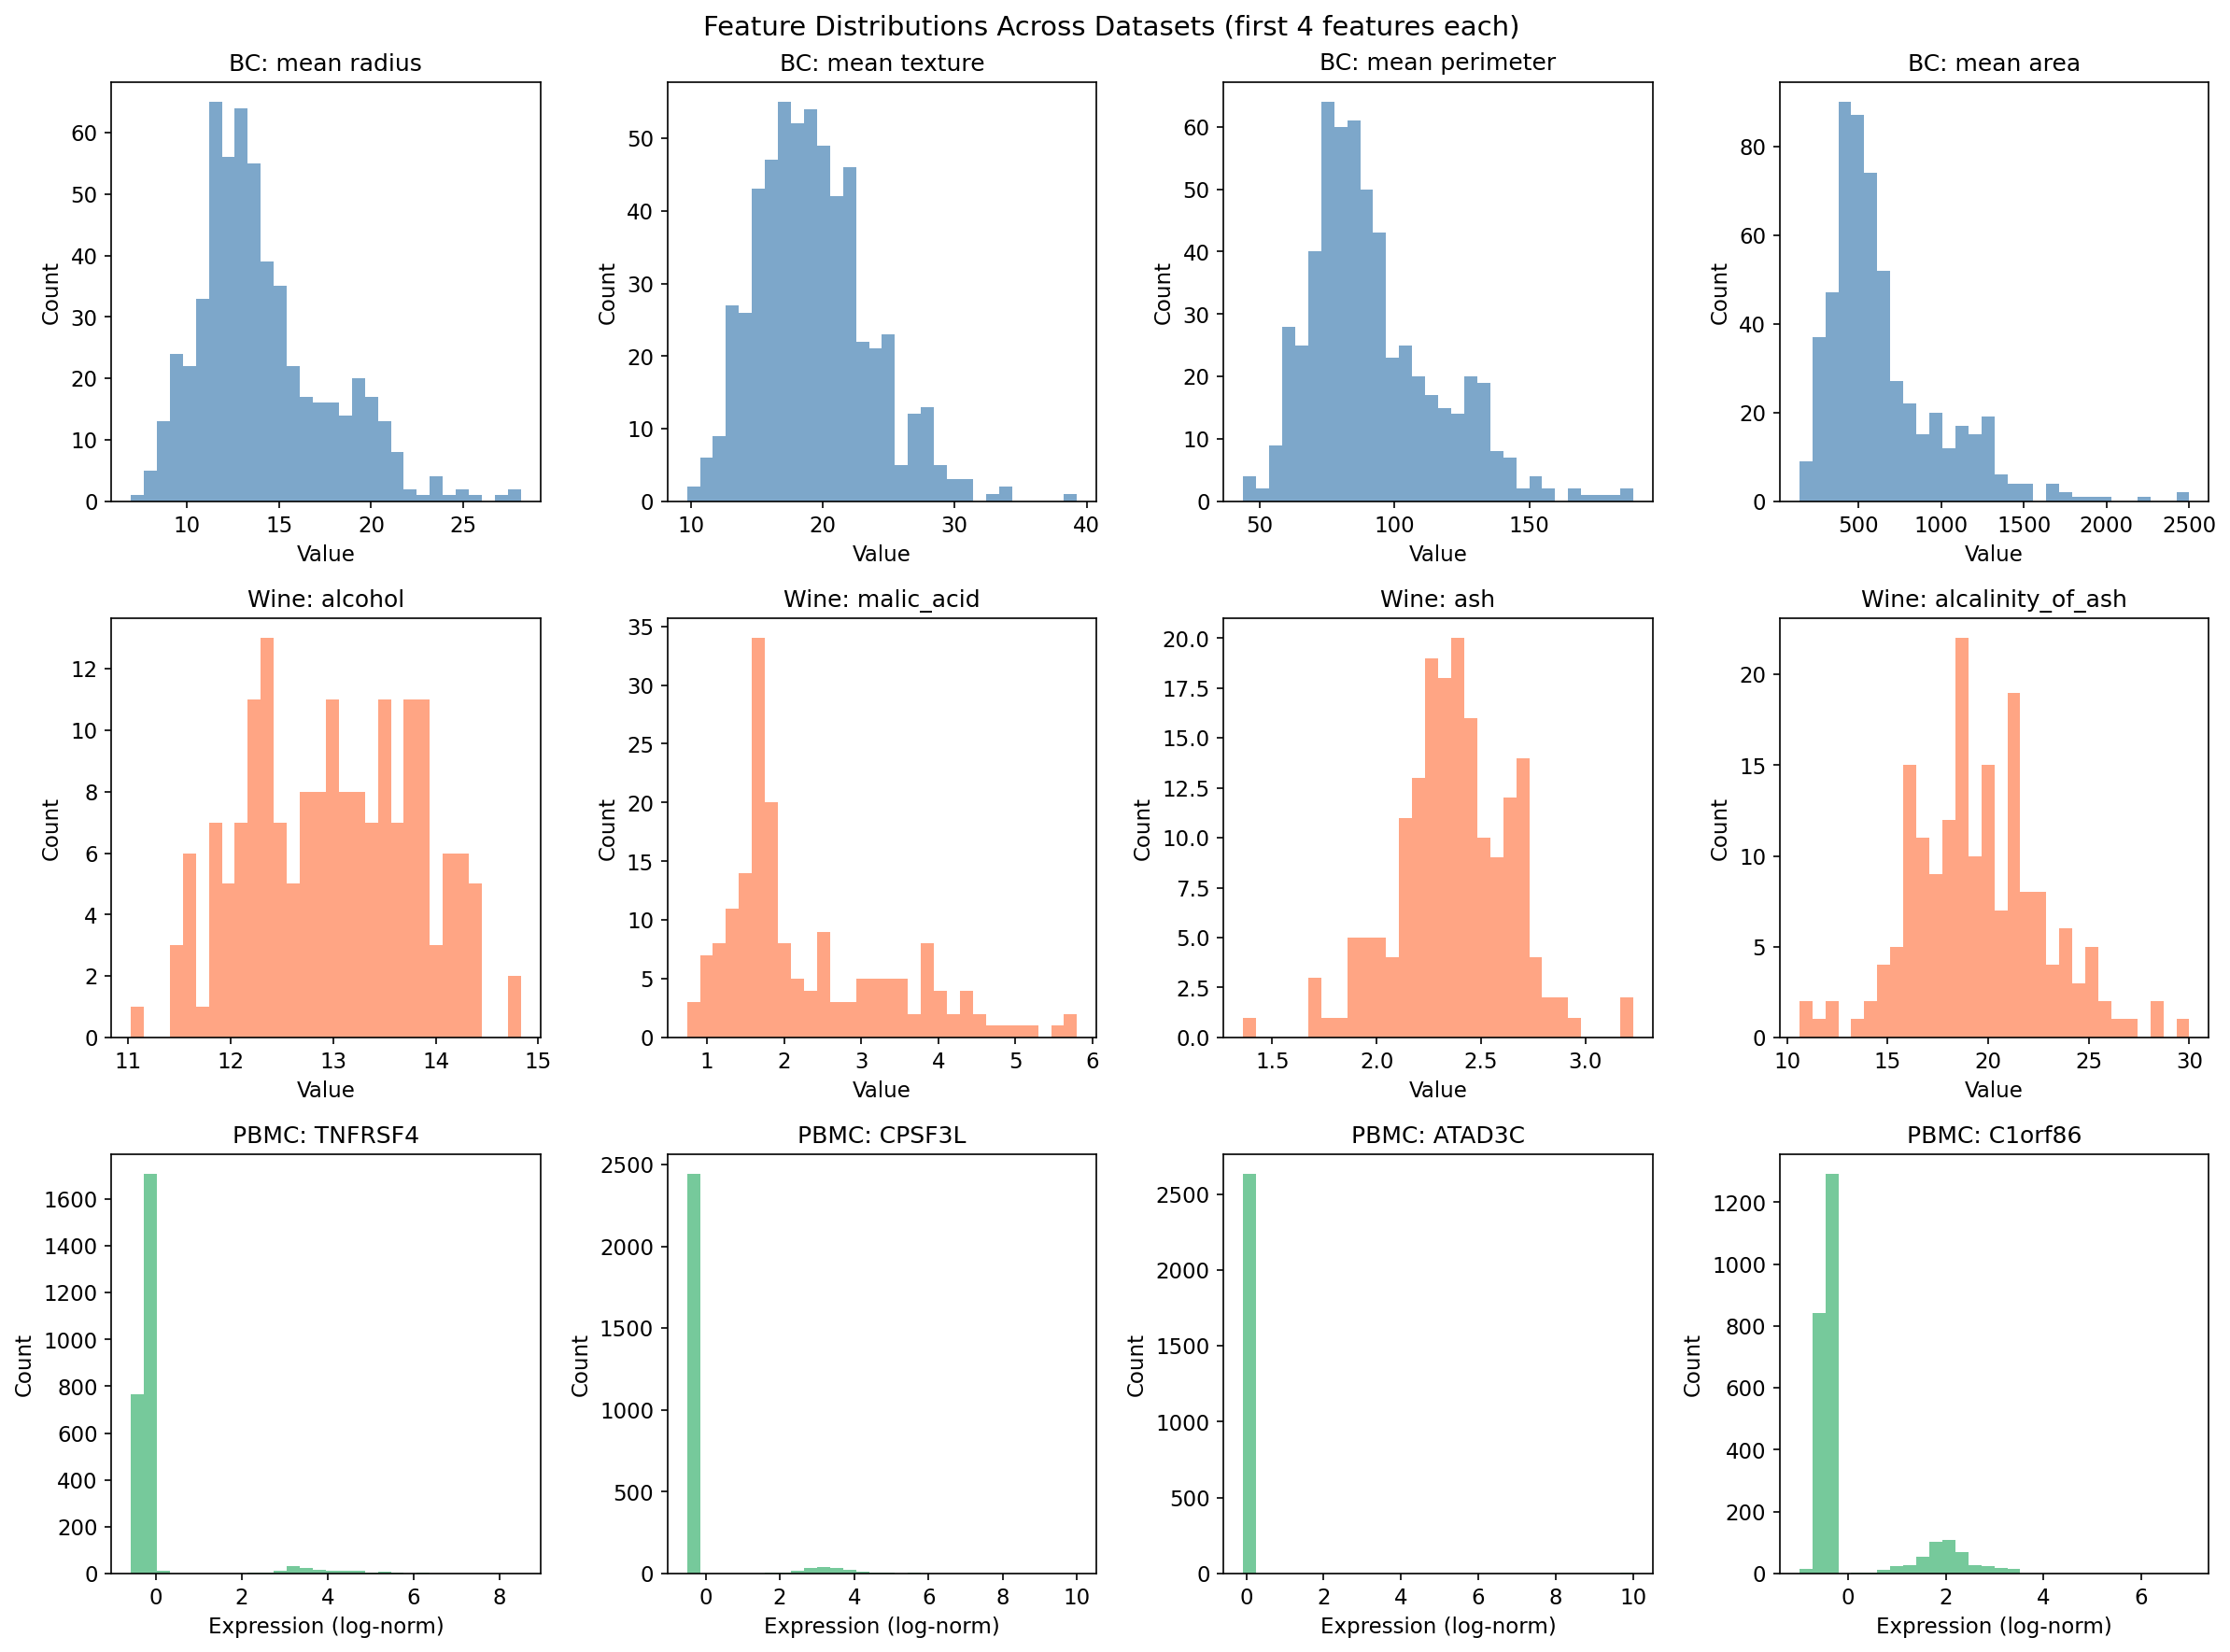

Figure saved: figures/01_dataset_feature_distributions.png


In [3]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle('Feature Distributions Across Datasets (first 4 features each)', fontsize=14)

for i, col in enumerate(X_bc.columns[:4]):
    axes[0, i].hist(X_bc[col], bins=30, color='steelblue', alpha=0.7)
    axes[0, i].set_title(f'BC: {col[:18]}')
    axes[0, i].set_xlabel('Value')
    axes[0, i].set_ylabel('Count')

for i, col in enumerate(X_wine.columns[:4]):
    axes[1, i].hist(X_wine[col], bins=30, color='coral', alpha=0.7)
    axes[1, i].set_title(f'Wine: {col[:18]}')
    axes[1, i].set_xlabel('Value')
    axes[1, i].set_ylabel('Count')

pbmc_df = pd.DataFrame(X_pbmc[:, :4], columns=[adata.var_names[i] for i in range(4)])
for i in range(4):
    axes[2, i].hist(pbmc_df.iloc[:, i], bins=30, color='mediumseagreen', alpha=0.7)
    axes[2, i].set_title(f'PBMC: {pbmc_df.columns[i]}')
    axes[2, i].set_xlabel('Expression (log-norm)')
    axes[2, i].set_ylabel('Count')

plt.tight_layout()
plt.savefig('figures/01_dataset_feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/01_dataset_feature_distributions.png")

## Baseline Clustering

### Metrics and their interpretation

**Adjusted Rand Index (ARI):** Measures agreement between two label assignments, corrected for chance. Values range from -1 to 1: ARI=1 means perfect agreement, ARI=0 means agreement no better than random assignment, and negative values indicate worse-than-random agreement. ARI is the primary metric for comparing clusterings to ground truth because it is symmetric and does not require cluster labels to match in name (it accounts for all possible label permutations).

**Normalised Mutual Information (NMI):** Also measures agreement between two label assignments, ranging from 0 to 1. Unlike ARI, NMI is not corrected for the number of clusters, so it can give inflated values when k is large. It is reported alongside ARI for completeness.

**Silhouette score:** An internal validation metric (does not require ground truth). For each sample, it measures how similar the sample is to its own cluster compared to the nearest other cluster. Values range from -1 to 1; higher values indicate better-defined clusters. Silhouette is useful when ground truth is unavailable, but it can favour compact, spherical clusters even when the true structure is not spherical.

**Why multiple metrics:** No single metric is reliable across all data geometries. A silhouette score can be high even when ARI is low, indicating the algorithm found compact clusters that do not correspond to the ground truth structure. Conversely, a high ARI alongside a modest silhouette can indicate that the biologically meaningful partition is not the geometrically simplest one. Using multiple metrics in combination, and checking whether they agree, is more trustworthy than relying on any one alone.

**What baselines are:** The baselines below represent the best expected performance under the most favourable conditions (correct k, standard scaling, default KMeans initialisation). All subsequent experiments are interpreted relative to the baseline. An experiment that reduces ARI substantially is evidence of sensitivity to that factor.

**PBMC baseline note:** The baseline ARI for PBMC measures how well KMeans with k=8 agrees with the Louvain-derived cell type labels. It is not measuring biological correctness. A high ARI means KMeans and Louvain partition the data similarly; it does not validate either partition as biologically true.

Evaluating k range for Breast Cancer...


Evaluating k range for Wine...


Evaluating k range for PBMC 3k (k=2 to 12)...


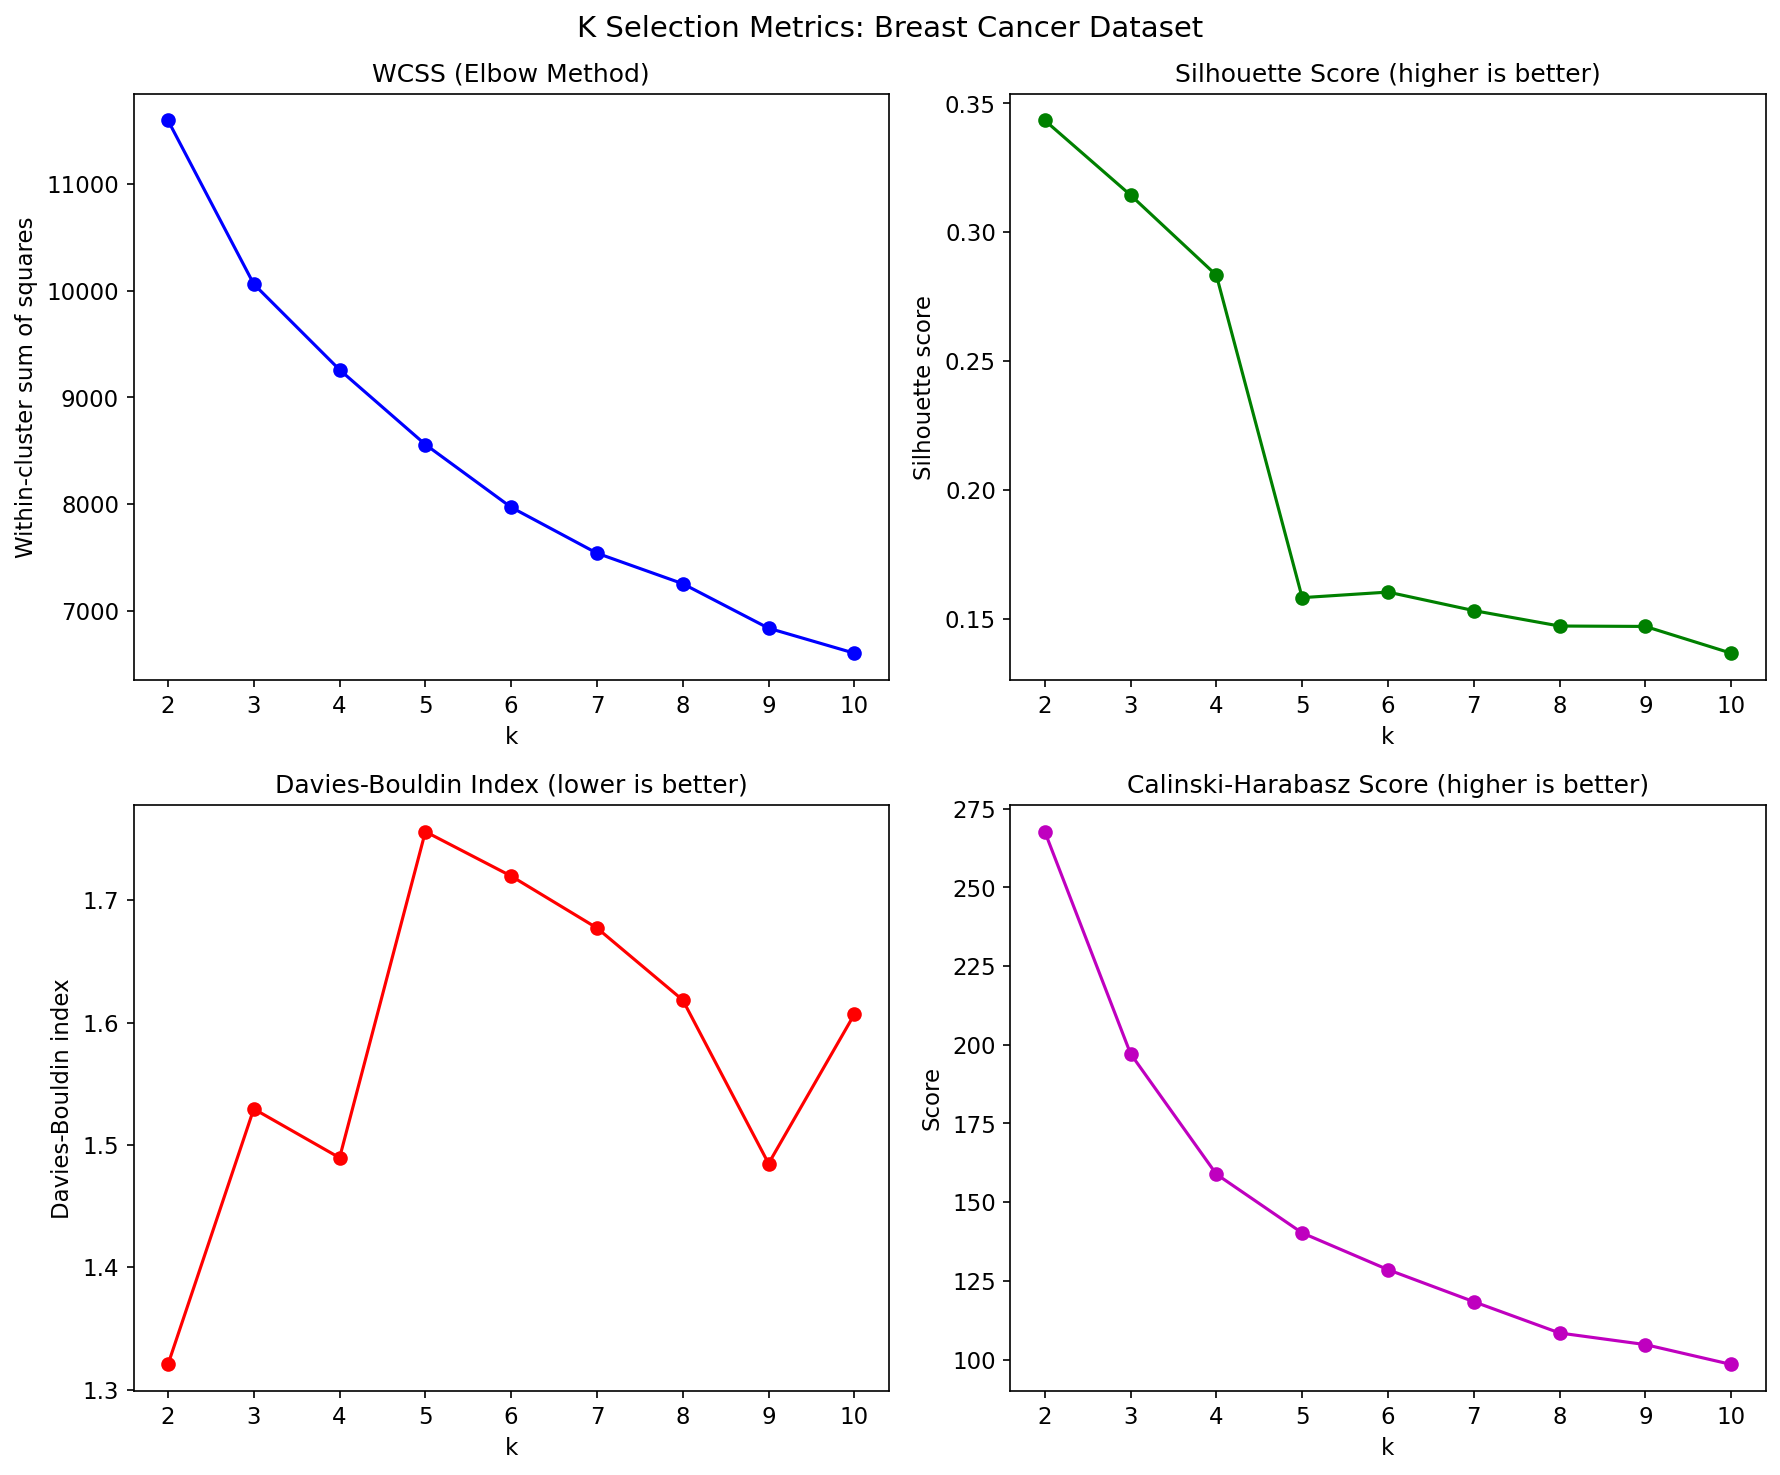

Figure saved: figures/02_k_selection_breast_cancer.png


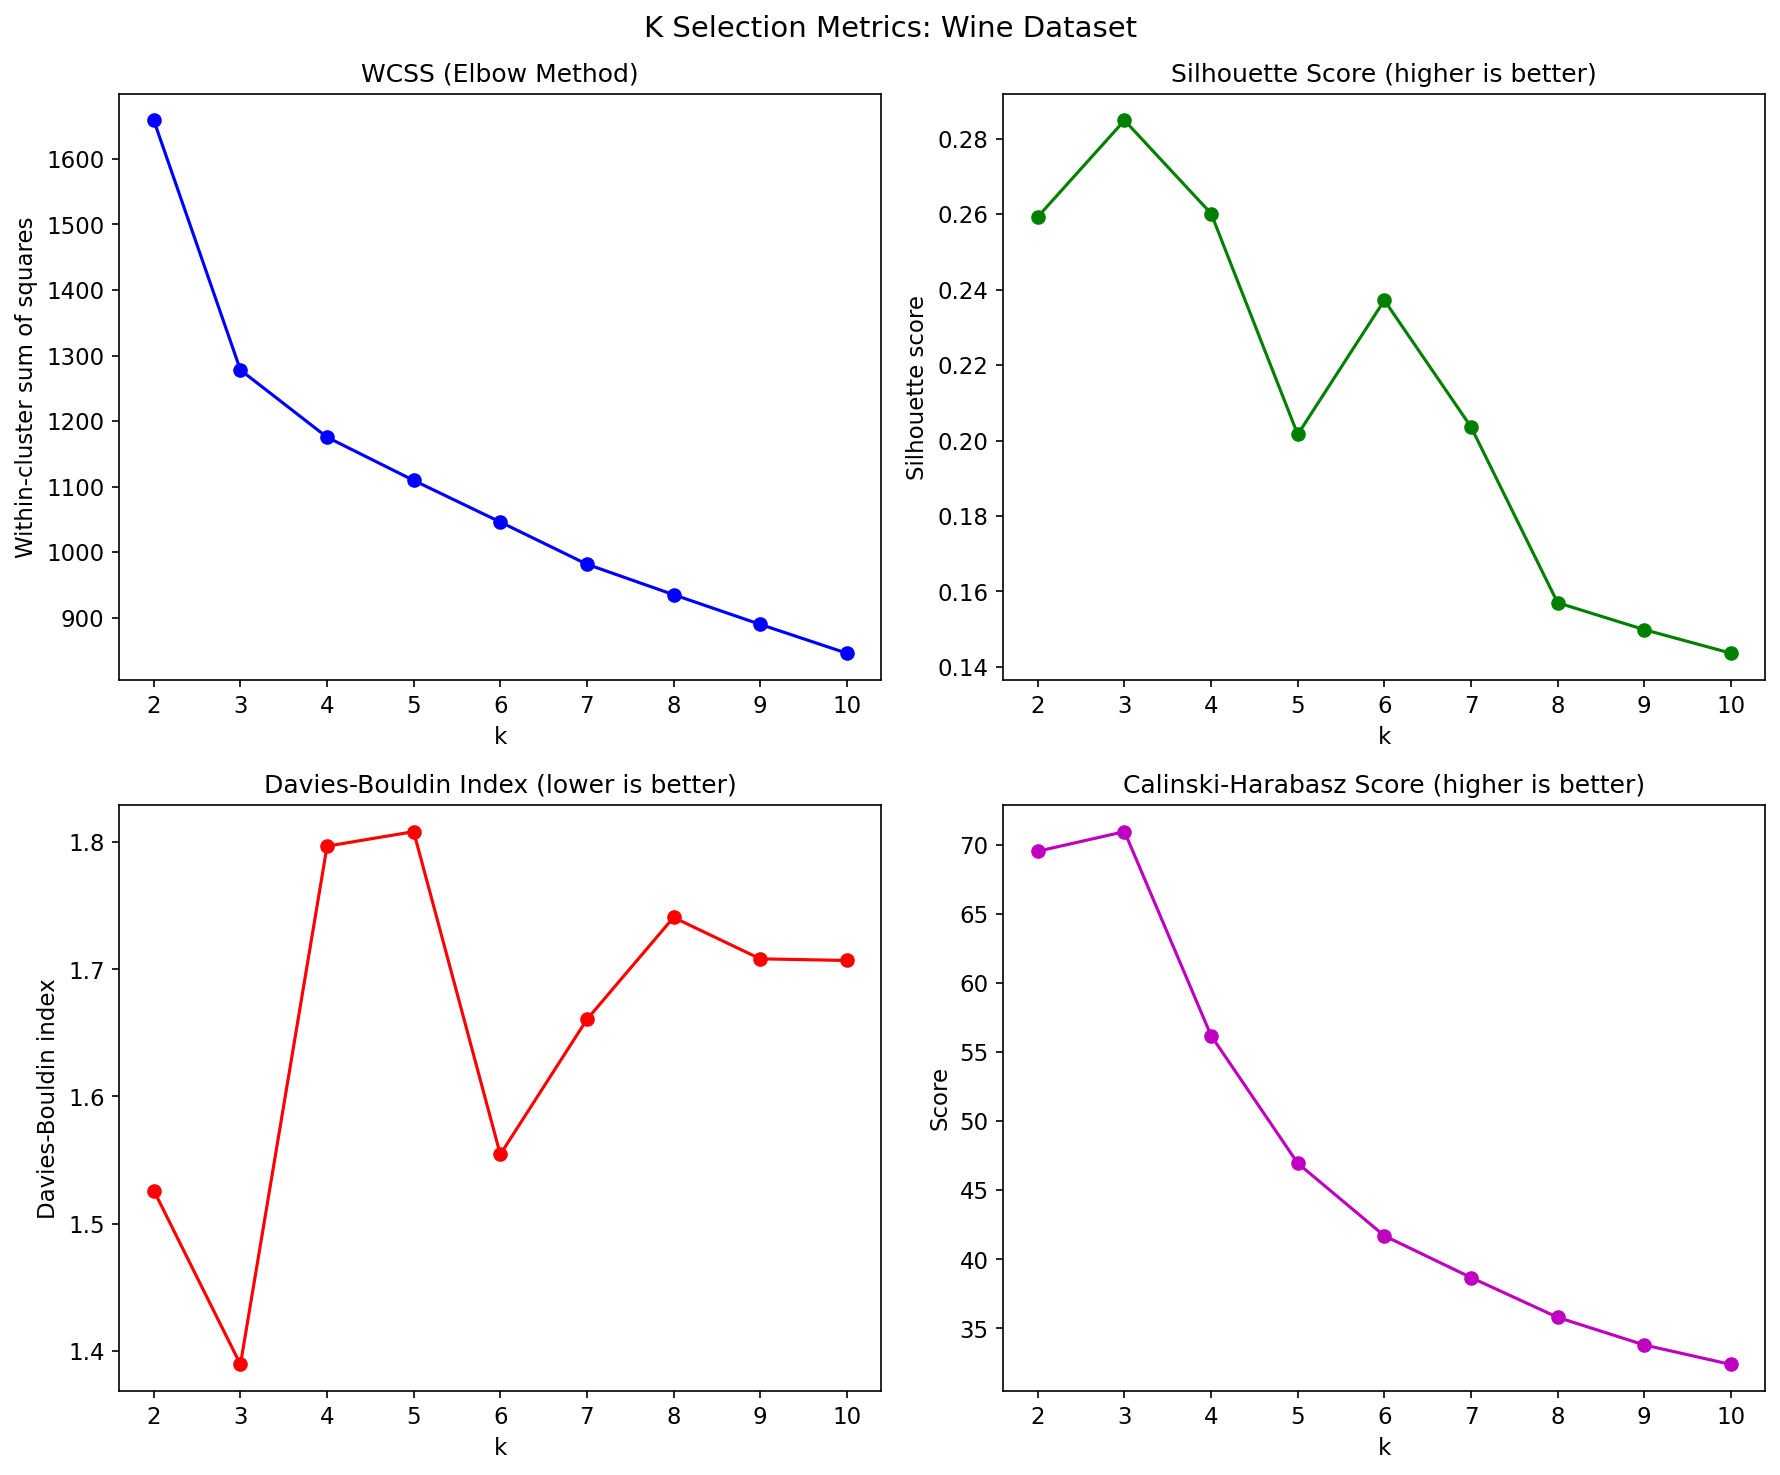

Figure saved: figures/03_k_selection_wine.png


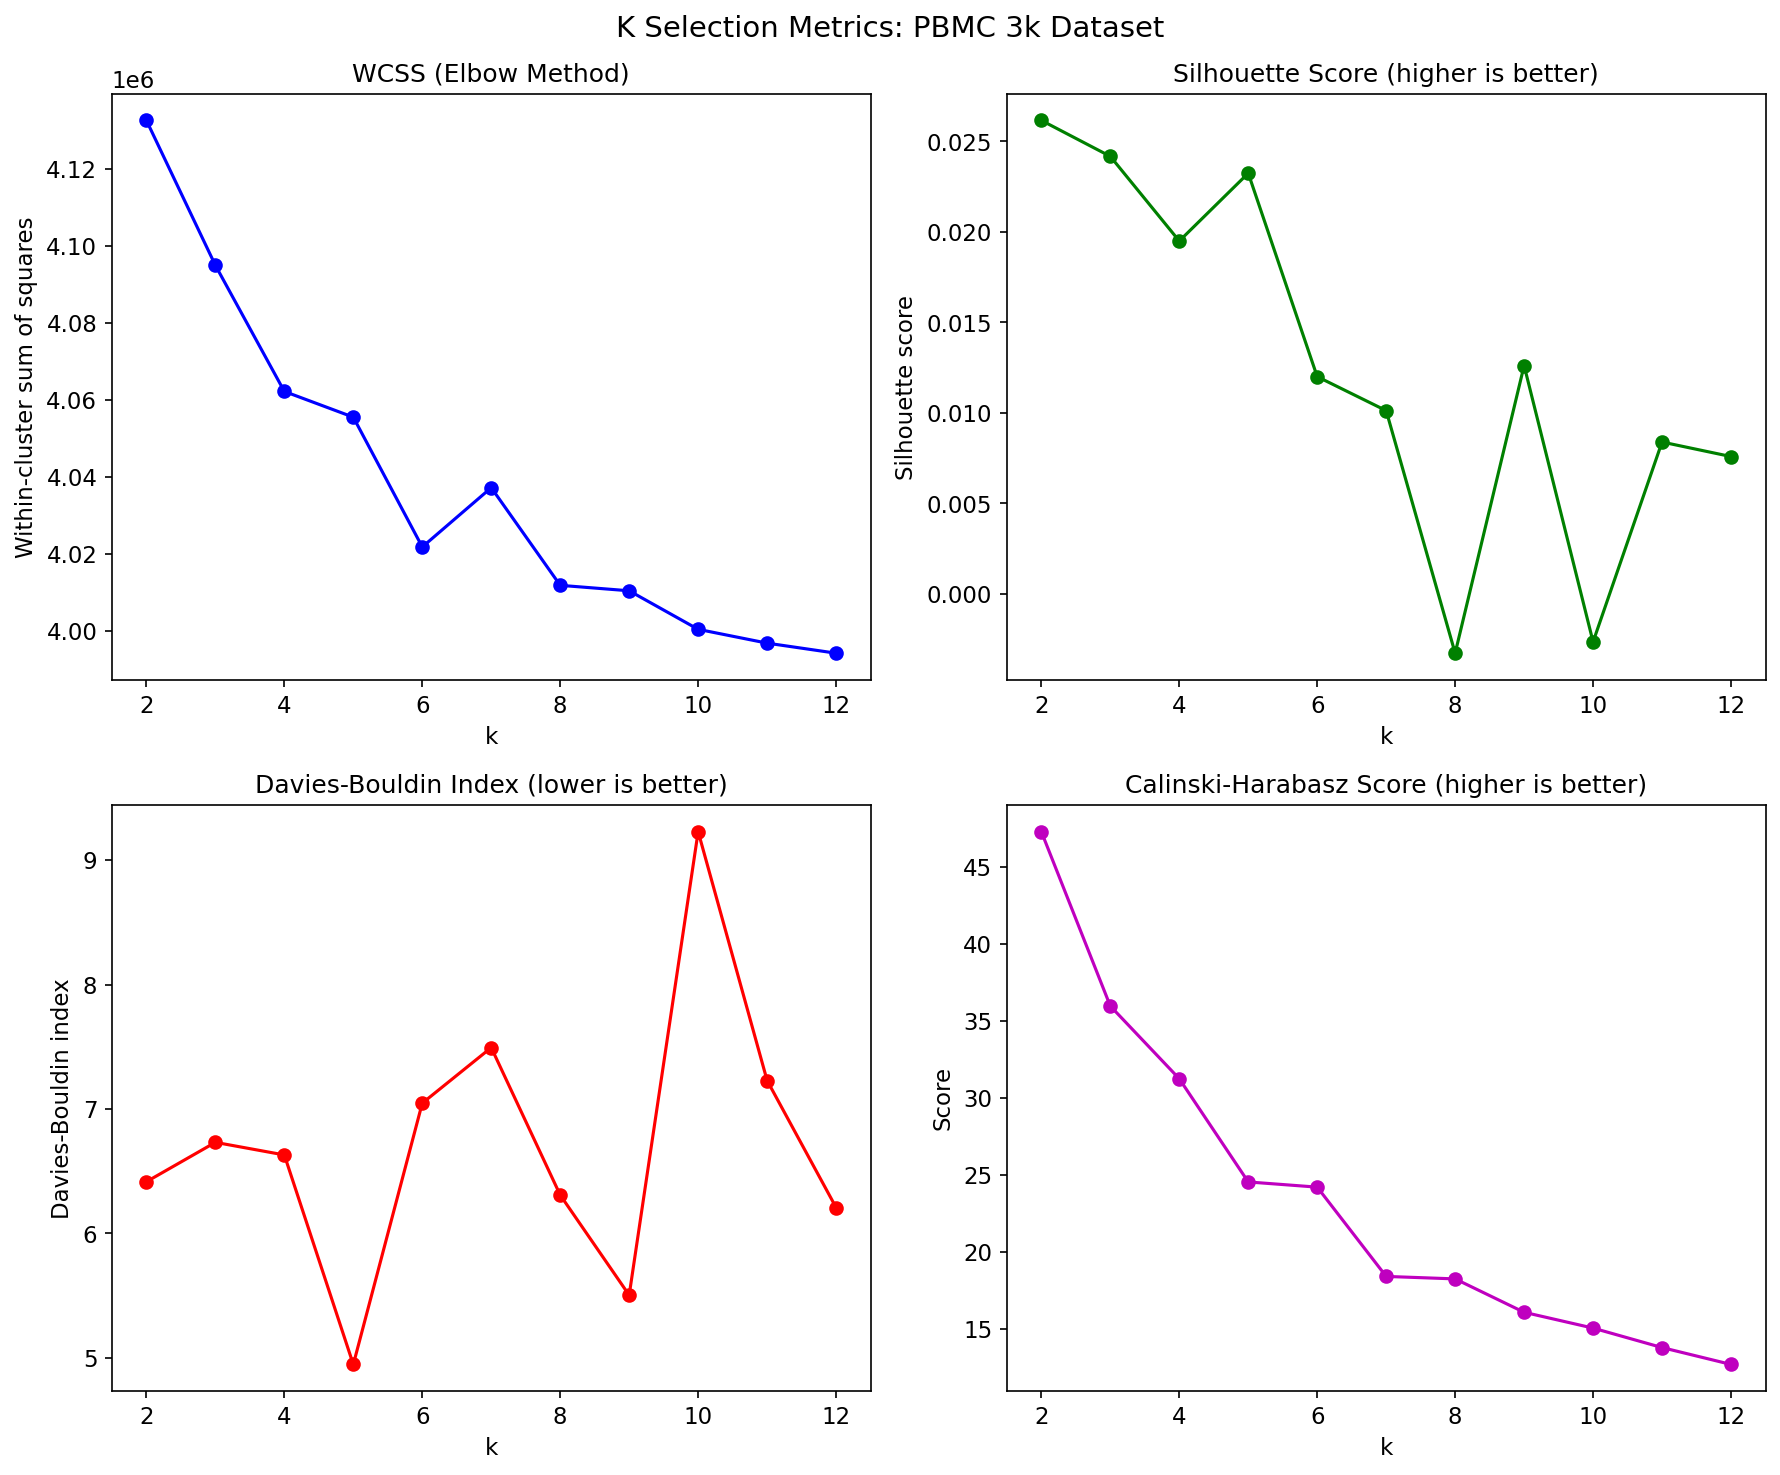

Figure saved: figures/03b_k_selection_pbmc.png

=== Baseline: Breast Cancer, k=2 ===
ARI vs ground truth: 0.6536
Silhouette score:    0.3434
NMI vs ground truth: 0.5324
Cluster sizes: {0: 375, 1: 194}

=== Baseline: Wine, k=3 ===
ARI vs ground truth: 0.8975
Silhouette score:    0.2849
NMI vs ground truth: 0.8759
Cluster sizes: {0: 65, 1: 51, 2: 62}



=== Baseline: PBMC 3k, k=8 ===
ARI vs ground truth: 0.7791
Silhouette score:    0.0029
NMI vs ground truth: 0.8108
Cluster sizes: {0: 471, 1: 353, 2: 11, 3: 13, 4: 6, 5: 1336, 6: 176, 7: 272}


In [4]:
def evaluate_k_range(X_scaled, k_range, random_state=42):
    """
    Evaluate multiple values of k using three internal validation metrics.
    Three metrics because no single metric is reliable; agreement is more trustworthy.
    - WCSS/Elbow: measures compactness but always improves with more clusters
    - Silhouette: measures separation vs cohesion, peaks at best k
    - Davies-Bouldin: lower is better, measures cluster overlap
    """
    results = {'k': list(k_range), 'wcss': [], 'silhouette': [],
               'davies_bouldin': [], 'calinski_harabasz': []}
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=random_state, n_init=10)
        labels = km.fit_predict(X_scaled)
        results['wcss'].append(km.inertia_)
        if k > 1:
            results['silhouette'].append(silhouette_score(X_scaled, labels, sample_size=min(1000, len(labels))))
            results['davies_bouldin'].append(davies_bouldin_score(X_scaled, labels))
            results['calinski_harabasz'].append(calinski_harabasz_score(X_scaled, labels))
        else:
            results['silhouette'].append(np.nan)
            results['davies_bouldin'].append(np.nan)
            results['calinski_harabasz'].append(np.nan)
    return results

def run_baseline(X_scaled, y_true, k, dataset_name, random_state=42):
    km = KMeans(n_clusters=k, random_state=random_state, n_init=10)
    labels = km.fit_predict(X_scaled)
    ari = adjusted_rand_score(y_true, labels)
    sil = silhouette_score(X_scaled, labels, sample_size=min(1000, len(labels)))
    nmi = normalized_mutual_info_score(y_true, labels)
    print(f"\n=== Baseline: {dataset_name}, k={k} ===")
    print(f"ARI vs ground truth: {ari:.4f}")
    print(f"Silhouette score:    {sil:.4f}")
    print(f"NMI vs ground truth: {nmi:.4f}")
    print(f"Cluster sizes: {pd.Series(labels).value_counts().sort_index().to_dict()}")
    return {'ari': ari, 'silhouette': sil, 'nmi': nmi, 'labels': labels}

# Scale sklearn datasets
scaler_bc = StandardScaler()
X_bc_scaled = scaler_bc.fit_transform(X_bc)
scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine)
# PBMC is already log-normalised and scaled by scanpy pipeline; use as-is
X_pbmc_scaled = X_pbmc

k_range = range(2, 11)
print("Evaluating k range for Breast Cancer...")
results_bc_k = evaluate_k_range(X_bc_scaled, k_range)
print("Evaluating k range for Wine...")
results_wine_k = evaluate_k_range(X_wine_scaled, k_range)
print("Evaluating k range for PBMC 3k (k=2 to 12)...")
results_pbmc_k = evaluate_k_range(X_pbmc_scaled, range(2, 13))

def plot_k_selection(results, title, filename):
    ks = results['k']
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    fig.suptitle(title, fontsize=14)
    axes[0,0].plot(ks, results['wcss'], 'b-o')
    axes[0,0].set_title('WCSS (Elbow Method)')
    axes[0,0].set_xlabel('k'); axes[0,0].set_ylabel('Within-cluster sum of squares')
    valid = [x for x in results['silhouette'] if not np.isnan(x)]
    valid_k = [k for k, x in zip(ks, results['silhouette']) if not np.isnan(x)]
    axes[0,1].plot(valid_k, valid, 'g-o')
    axes[0,1].set_title('Silhouette Score (higher is better)')
    axes[0,1].set_xlabel('k'); axes[0,1].set_ylabel('Silhouette score')
    valid_db = [x for x in results['davies_bouldin'] if not np.isnan(x)]
    axes[1,0].plot(valid_k, valid_db, 'r-o')
    axes[1,0].set_title('Davies-Bouldin Index (lower is better)')
    axes[1,0].set_xlabel('k'); axes[1,0].set_ylabel('Davies-Bouldin index')
    valid_ch = [x for x in results['calinski_harabasz'] if not np.isnan(x)]
    axes[1,1].plot(valid_k, valid_ch, 'm-o')
    axes[1,1].set_title('Calinski-Harabasz Score (higher is better)')
    axes[1,1].set_xlabel('k'); axes[1,1].set_ylabel('Score')
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Figure saved: {filename}")

plot_k_selection(results_bc_k, 'K Selection Metrics: Breast Cancer Dataset', 'figures/02_k_selection_breast_cancer.png')
plot_k_selection(results_wine_k, 'K Selection Metrics: Wine Dataset', 'figures/03_k_selection_wine.png')
plot_k_selection(results_pbmc_k, 'K Selection Metrics: PBMC 3k Dataset', 'figures/03b_k_selection_pbmc.png')

baseline_bc = run_baseline(X_bc_scaled, y_bc, k=2, dataset_name='Breast Cancer')
baseline_wine = run_baseline(X_wine_scaled, y_wine, k=3, dataset_name='Wine')
baseline_pbmc = run_baseline(X_pbmc_scaled, y_pbmc, k=8, dataset_name='PBMC 3k')

## Bootstrap Stability

### What stability means and how it is measured

A clustering result is stable if it would re-emerge with slightly different data. Bootstrap stability measures this by repeatedly subsampling the dataset (here: 80% of samples without replacement), clustering each subsample independently, and computing pairwise ARI between runs on the shared samples.

**Interpreting results:**
- Mean pairwise ARI above 0.8: the clustering structure is robust. Adding or removing a random 20% of the data does not substantially change which clusters form. This is strong evidence that the cluster structure is a property of the data, not a statistical accident.
- Mean pairwise ARI below 0.5: the clustering is sensitive to which samples are included. Small perturbations to the data produce qualitatively different partitions. Conclusions drawn from any single run should be treated with caution.
- Values between 0.5 and 0.8: moderate stability. The main structure is probably real but fine-grained details may be unstable.

**Why pairwise ARI on shared samples:** Each subsample contains different cells/samples. Direct comparison of full-run labels is impossible. By restricting to samples that appear in both runs, we measure whether the same samples are assigned to corresponding clusters across runs, abstracting away label permutation.

**Stability vs accuracy:** A clustering can be highly stable but wrong (if the algorithm consistently finds the same structure that does not correspond to ground truth), and it can be accurate on average but unstable (if it sometimes recovers ground truth and sometimes does not). The subsequent scatter plots compare stability against ARI to distinguish these cases.

**PBMC caveat:** For PBMC, high bootstrap stability means KMeans consistently finds the same partition of the cells across subsamples. This is meaningful evidence that the data has robust cluster structure. However, stability does not validate the clusters against biological truth, only against one particular Louvain solution. A stable KMeans partition that disagrees with Louvain may still be biologically coherent.

### Justification for n_iterations=50 and subsample_fraction=0.8

See the Key Methodological Decisions section above for the full argument. In brief: 50 iterations is sufficient for stable mean ARI estimation (Efron and Tibshirani, 1993; Ben-Hur et al., 2002), and 0.8 is the most common subsampling fraction in the clustering stability literature (Ben-Hur et al., 2002). The sensitivity of the stability estimate to subsample fraction is directly tested in the second plot of this section.


Running bootstrap stability: Breast Cancer...


BC: mean ARI=0.9505, std=0.0460
Running bootstrap stability: Wine...


Wine: mean ARI=0.9648, std=0.0423
Running bootstrap stability: PBMC 3k (k=8)...


PBMC: mean ARI=0.7659, std=0.1029


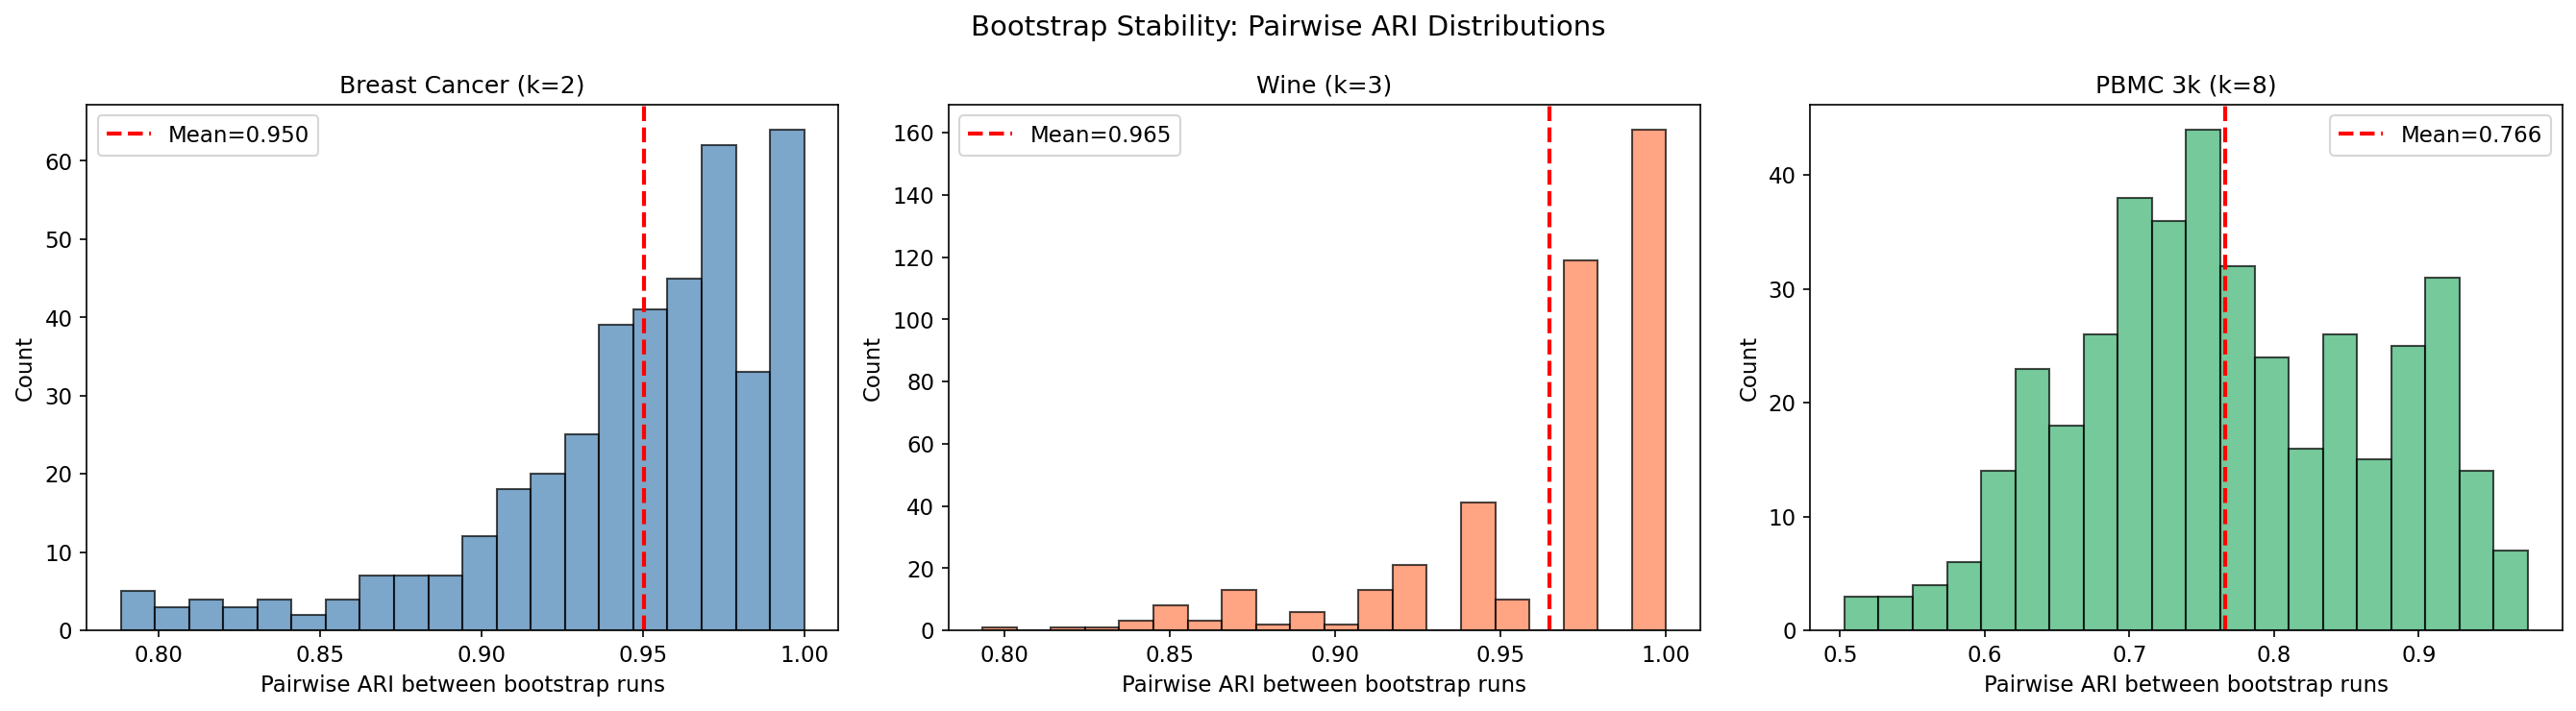

Figure saved: figures/04_bootstrap_stability_distributions.png
  fraction=0.5...


    BC=0.930, Wine=0.905, PBMC=0.761
  fraction=0.6...


    BC=0.943, Wine=0.926, PBMC=0.745
  fraction=0.7...


    BC=0.940, Wine=0.942, PBMC=0.743
  fraction=0.8...


    BC=0.953, Wine=0.960, PBMC=0.782
  fraction=0.9...


    BC=0.971, Wine=0.978, PBMC=0.776


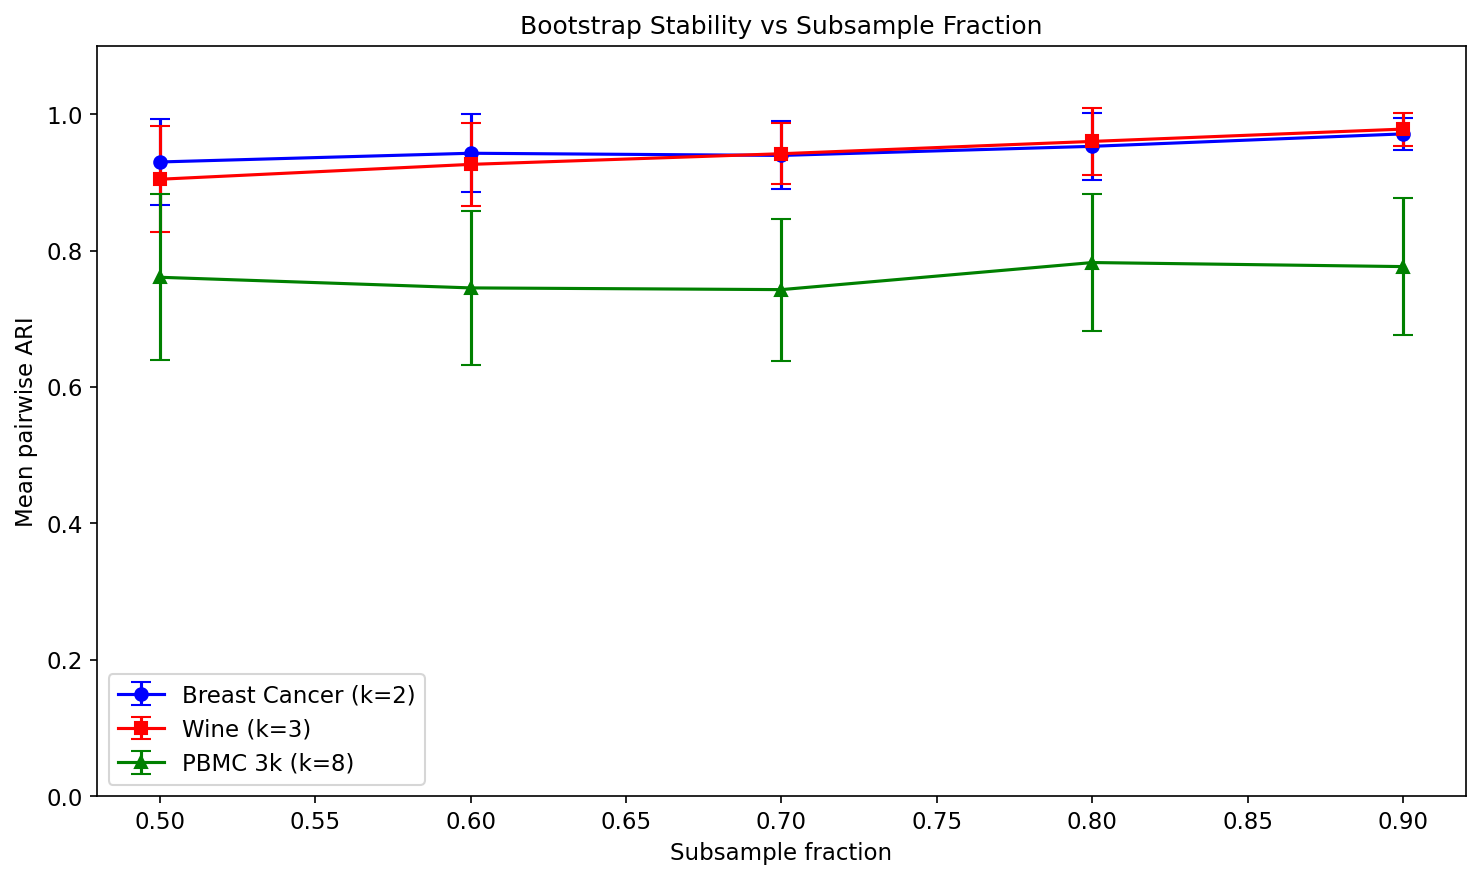

Figure saved: figures/05_bootstrap_ari_vs_subsample_fraction.png


In [5]:
def bootstrap_stability(X_scaled, k, n_iterations=50, subsample_fraction=0.8, random_state=42):
    """
    Repeatedly subsample the data and cluster each subsample.
    Measure pairwise ARI on shared samples.
    High mean ARI (>0.8): stable structure.
    Low mean ARI (<0.5): sensitivity to which samples are included.
    """
    rng = np.random.RandomState(random_state)
    n_samples = X_scaled.shape[0]
    n_subsample = int(n_samples * subsample_fraction)
    all_labels = []
    all_indices = []
    for i in range(n_iterations):
        idx = rng.choice(n_samples, size=n_subsample, replace=False)
        X_sub = X_scaled[idx]
        km = KMeans(n_clusters=k, random_state=rng.randint(10000), n_init=10)
        labels = km.fit_predict(X_sub)
        all_labels.append(labels)
        all_indices.append(idx)
    ari_scores = []
    for i in range(n_iterations):
        for j in range(i+1, min(i+10, n_iterations)):
            shared = np.intersect1d(all_indices[i], all_indices[j])
            if len(shared) < 10:
                continue
            pos_i = [np.where(all_indices[i] == s)[0][0] for s in shared]
            pos_j = [np.where(all_indices[j] == s)[0][0] for s in shared]
            labels_i = all_labels[i][pos_i]
            labels_j = all_labels[j][pos_j]
            ari_scores.append(adjusted_rand_score(labels_i, labels_j))
    return {
        'ari_scores': ari_scores,
        'mean_ari': np.mean(ari_scores),
        'std_ari': np.std(ari_scores),
        'median_ari': np.median(ari_scores)
    }

print("Running bootstrap stability: Breast Cancer...")
stab_bc = bootstrap_stability(X_bc_scaled, k=2, n_iterations=50)
print(f"BC: mean ARI={stab_bc['mean_ari']:.4f}, std={stab_bc['std_ari']:.4f}")

print("Running bootstrap stability: Wine...")
stab_wine = bootstrap_stability(X_wine_scaled, k=3, n_iterations=50)
print(f"Wine: mean ARI={stab_wine['mean_ari']:.4f}, std={stab_wine['std_ari']:.4f}")

print("Running bootstrap stability: PBMC 3k (k=8)...")
stab_pbmc = bootstrap_stability(X_pbmc_scaled, k=8, n_iterations=50)
print(f"PBMC: mean ARI={stab_pbmc['mean_ari']:.4f}, std={stab_pbmc['std_ari']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Bootstrap Stability: Pairwise ARI Distributions', fontsize=14)

for ax, stab, name, color in [
    (axes[0], stab_bc, 'Breast Cancer (k=2)', 'steelblue'),
    (axes[1], stab_wine, 'Wine (k=3)', 'coral'),
    (axes[2], stab_pbmc, 'PBMC 3k (k=8)', 'mediumseagreen'),
]:
    ax.hist(stab['ari_scores'], bins=20, color=color, alpha=0.7, edgecolor='black')
    ax.axvline(stab['mean_ari'], color='red', linestyle='--', linewidth=2, label=f"Mean={stab['mean_ari']:.3f}")
    ax.set_title(name)
    ax.set_xlabel('Pairwise ARI between bootstrap runs')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.savefig('figures/04_bootstrap_stability_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/04_bootstrap_stability_distributions.png")

# Stability vs subsample fraction
fractions = [0.5, 0.6, 0.7, 0.8, 0.9]
bc_by_frac, wine_by_frac, pbmc_by_frac = [], [], []

for frac in fractions:
    print(f"  fraction={frac}...")
    s_bc = bootstrap_stability(X_bc_scaled, k=2, n_iterations=30, subsample_fraction=frac)
    s_wine = bootstrap_stability(X_wine_scaled, k=3, n_iterations=30, subsample_fraction=frac)
    s_pbmc = bootstrap_stability(X_pbmc_scaled, k=8, n_iterations=30, subsample_fraction=frac)
    bc_by_frac.append((s_bc['mean_ari'], s_bc['std_ari']))
    wine_by_frac.append((s_wine['mean_ari'], s_wine['std_ari']))
    pbmc_by_frac.append((s_pbmc['mean_ari'], s_pbmc['std_ari']))
    print(f"    BC={s_bc['mean_ari']:.3f}, Wine={s_wine['mean_ari']:.3f}, PBMC={s_pbmc['mean_ari']:.3f}")

fig, ax = plt.subplots(figsize=(10, 6))
for label, data, fmt in [
    ('Breast Cancer (k=2)', bc_by_frac, 'b-o'),
    ('Wine (k=3)', wine_by_frac, 'r-s'),
    ('PBMC 3k (k=8)', pbmc_by_frac, 'g-^'),
]:
    means = [x[0] for x in data]
    stds = [x[1] for x in data]
    ax.errorbar(fractions, means, yerr=stds, fmt=fmt, capsize=5, label=label)
ax.set_xlabel('Subsample fraction')
ax.set_ylabel('Mean pairwise ARI')
ax.set_title('Bootstrap Stability vs Subsample Fraction')
ax.legend()
ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.savefig('figures/05_bootstrap_ari_vs_subsample_fraction.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/05_bootstrap_ari_vs_subsample_fraction.png")

## Preprocessing Sensitivity

### Why preprocessing is not neutral

Preprocessing is often treated as a housekeeping step, but it is a substantive analytical choice that can qualitatively change clustering conclusions. The core issue is that distance-based clustering algorithms treat all dimensions as equally important. Preprocessing determines what "equal importance" means in practice.

**StandardScaler (z-score normalisation):** Each feature is centred to zero mean and scaled to unit variance. This makes every feature contribute equally to Euclidean distance, regardless of its natural scale. This is appropriate when features are measured in different units and there is no a priori reason to weight one feature more than another.

**MinMaxScaler:** Each feature is scaled to the range [0, 1]. The relative distances between features are preserved within each feature, but features with outliers will compress the majority of values near one end of the range. This is less robust to outliers than StandardScaler.

**RobustScaler:** Uses median and interquartile range instead of mean and standard deviation. This is more resistant to outliers than StandardScaler and is appropriate when feature distributions have heavy tails or extreme values.

**No scaling (raw features):** Distance is dominated by high-magnitude features. For the breast cancer dataset, this means area and perimeter dominate; for wine, proline dominates. This is rarely the right choice for general-purpose clustering, but it corresponds to implicit weighting by natural scale, which might be appropriate in some domain contexts.

**PBMC preprocessing: biologically motivated choices**

For single-cell RNA-seq data, preprocessing choices are not arbitrary. They are motivated by specific technical and biological properties of the data:

- **Library size normalisation:** Different cells are captured at different sequencing depths (some cells produce more total reads than others). This is a technical artefact. Normalising to a fixed total count per cell (10,000 is conventional) removes cell-to-cell technical variation before measuring biological differences.
- **Log transformation (log1p):** Gene expression counts have very skewed distributions: most genes are expressed at low levels, and a small number of highly expressed genes can dominate distance calculations. Log transformation compresses the dynamic range and stabilises variance, making the data more amenable to distance-based methods.
- **Scaling to zero mean and unit variance per gene:** After log transformation, some genes still have higher variance than others simply because they are expressed in more cells. Scaling makes every gene contribute equally to downstream distance calculations.

The preprocessing comparison for PBMC therefore compares biologically motivated pipeline stages, not arbitrary scaling choices. The question being asked is: how much do these justified preprocessing steps change the clustering outcome, and does each step move results in the expected direction?

Loading raw PBMC 3k for preprocessing sensitivity...


Running preprocessing sensitivity: Breast Cancer...


Running preprocessing sensitivity: Wine...
Running preprocessing sensitivity: PBMC 3k...


  Raw counts (top 2000 var genes): ARI=0.354, Sil=0.099


  Normalised only (no log): ARI=0.450, Sil=0.072


  Normalised + log1p: ARI=0.579, Sil=0.010


  Normalised + log1p + scaled: ARI=0.633, Sil=0.005


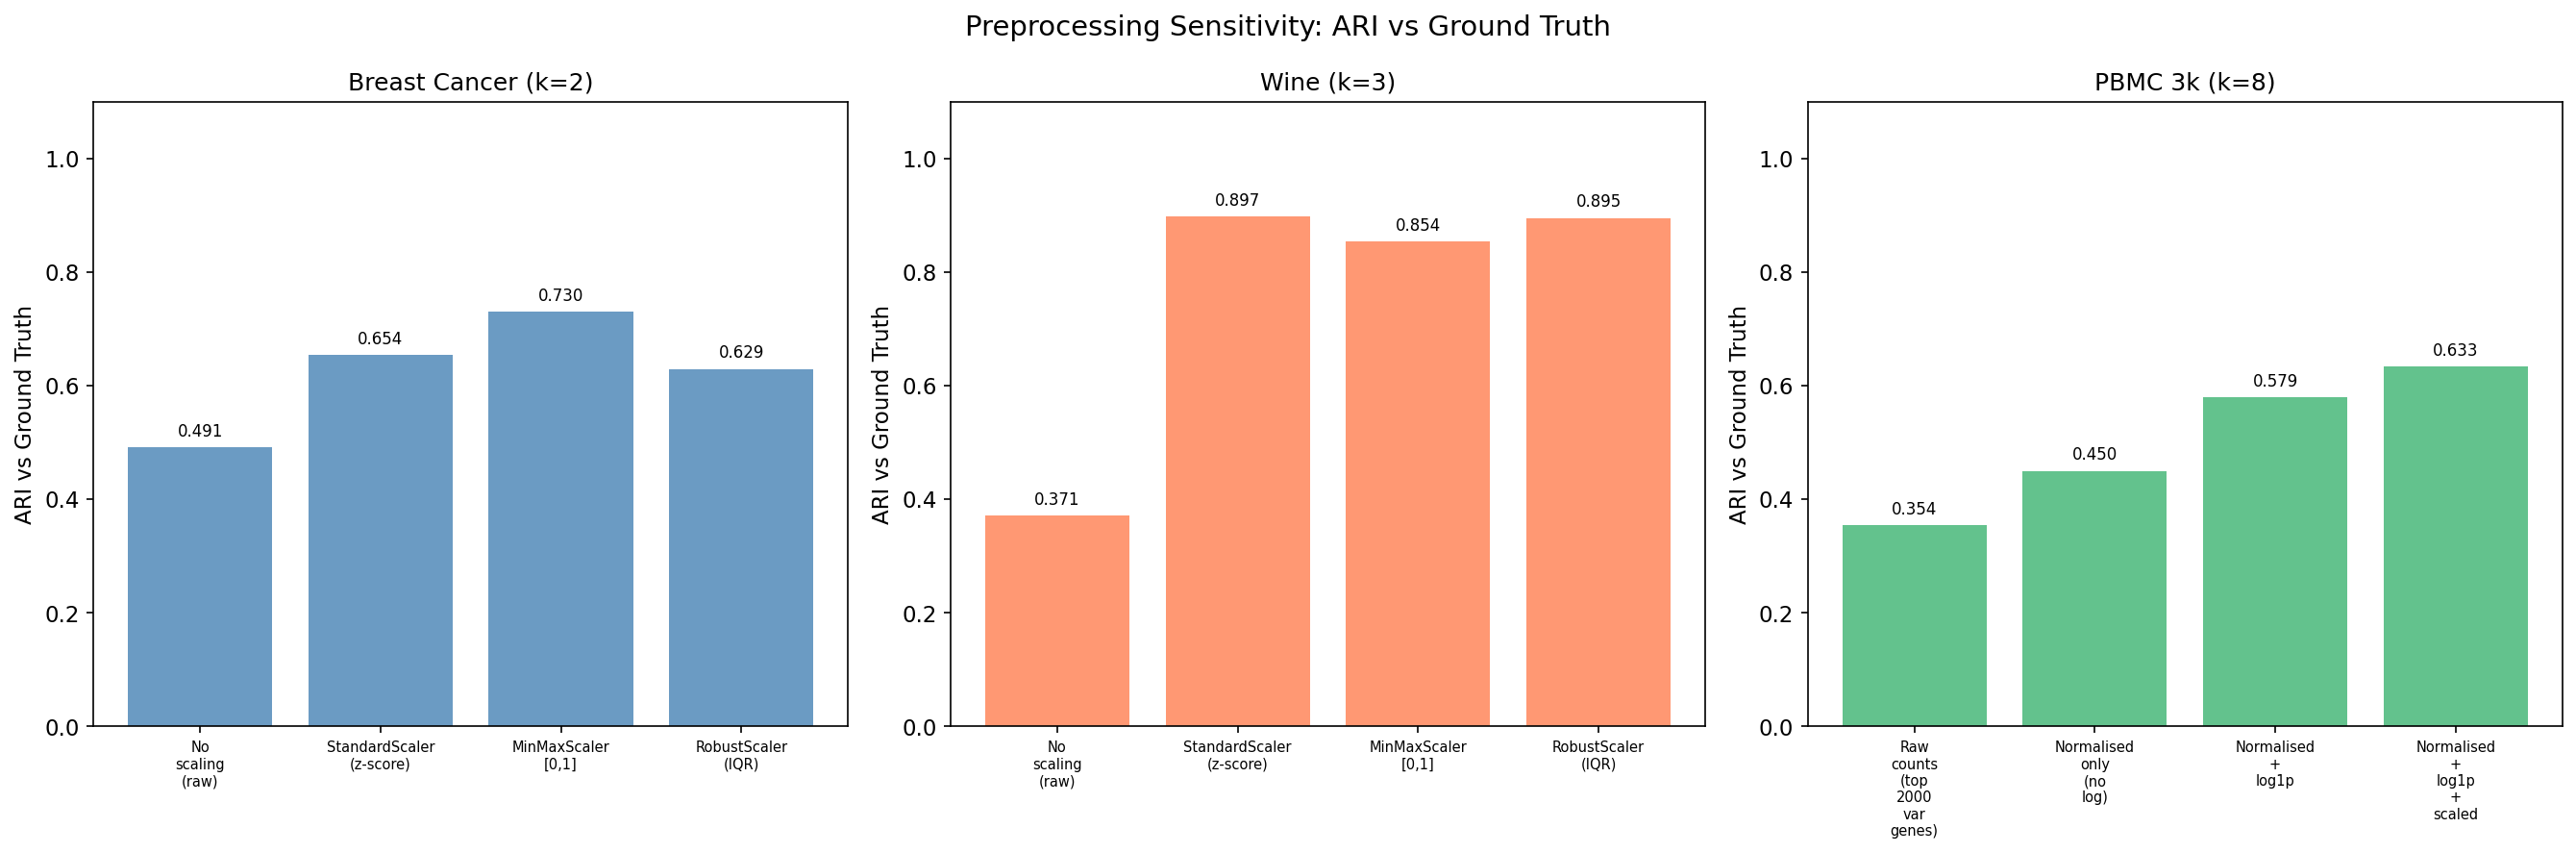

Figure saved: figures/06_preprocessing_ari_vs_groundtruth.png


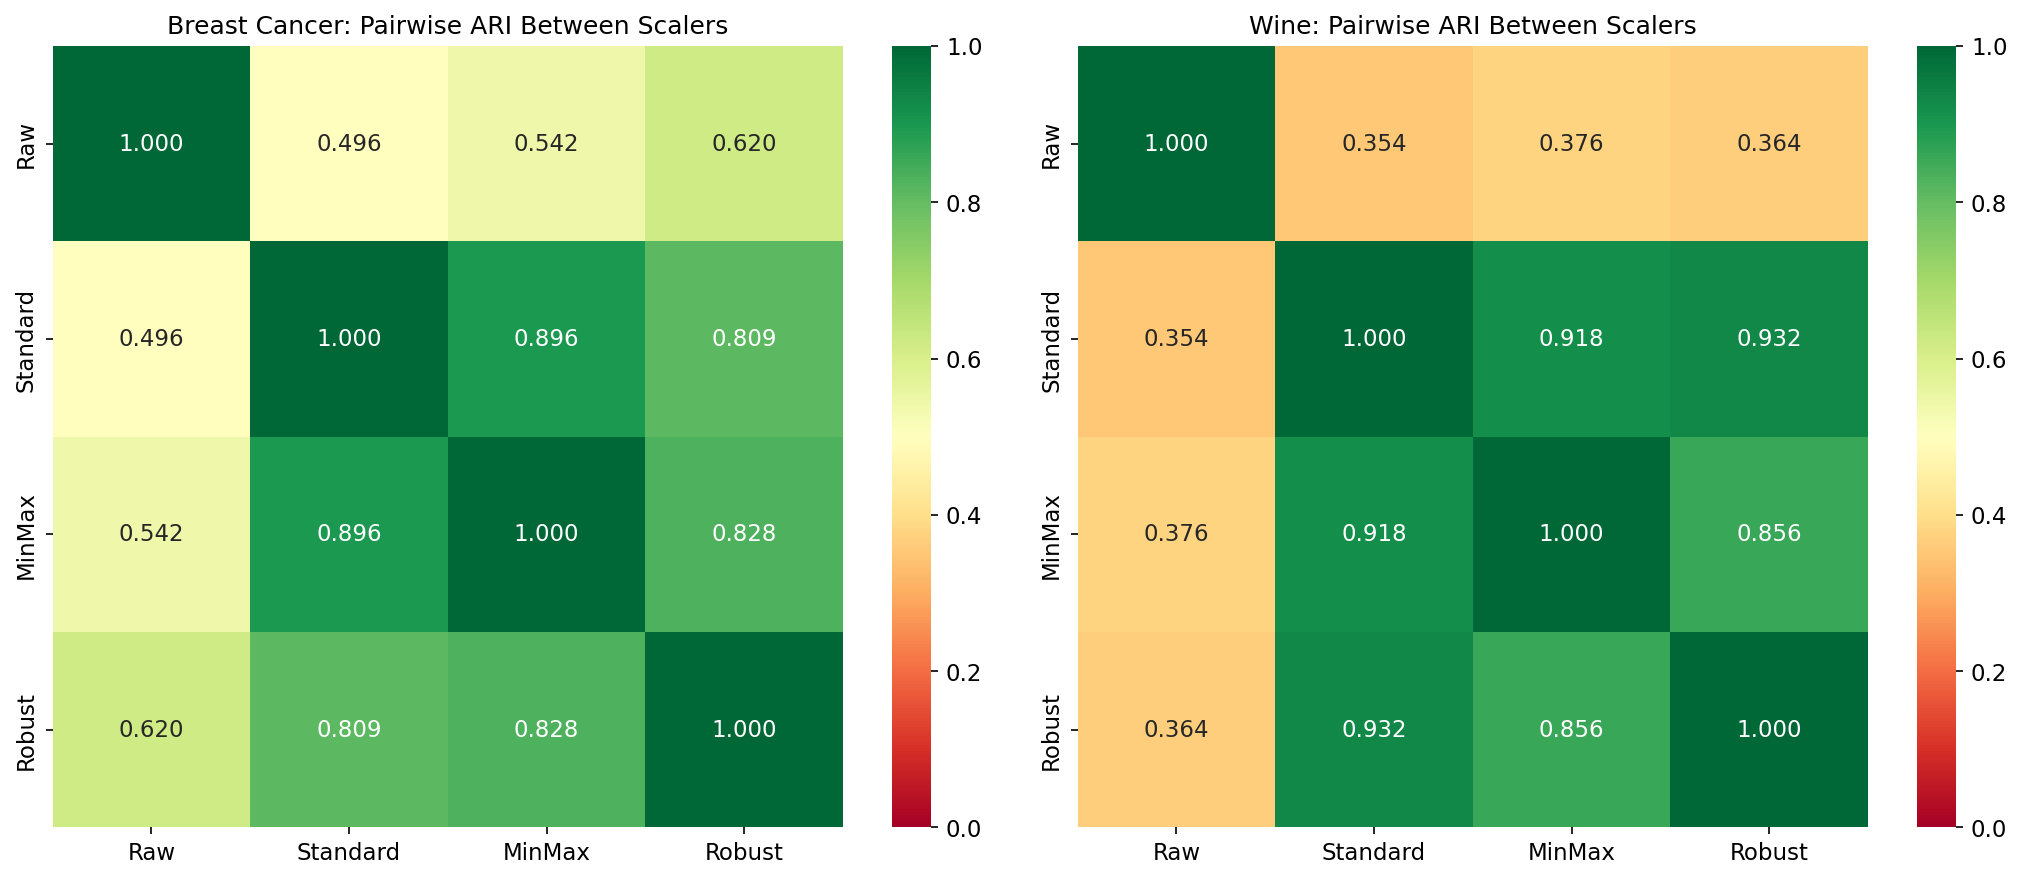

Figure saved: figures/07_preprocessing_pairwise_ari_heatmap_bc_wine.png


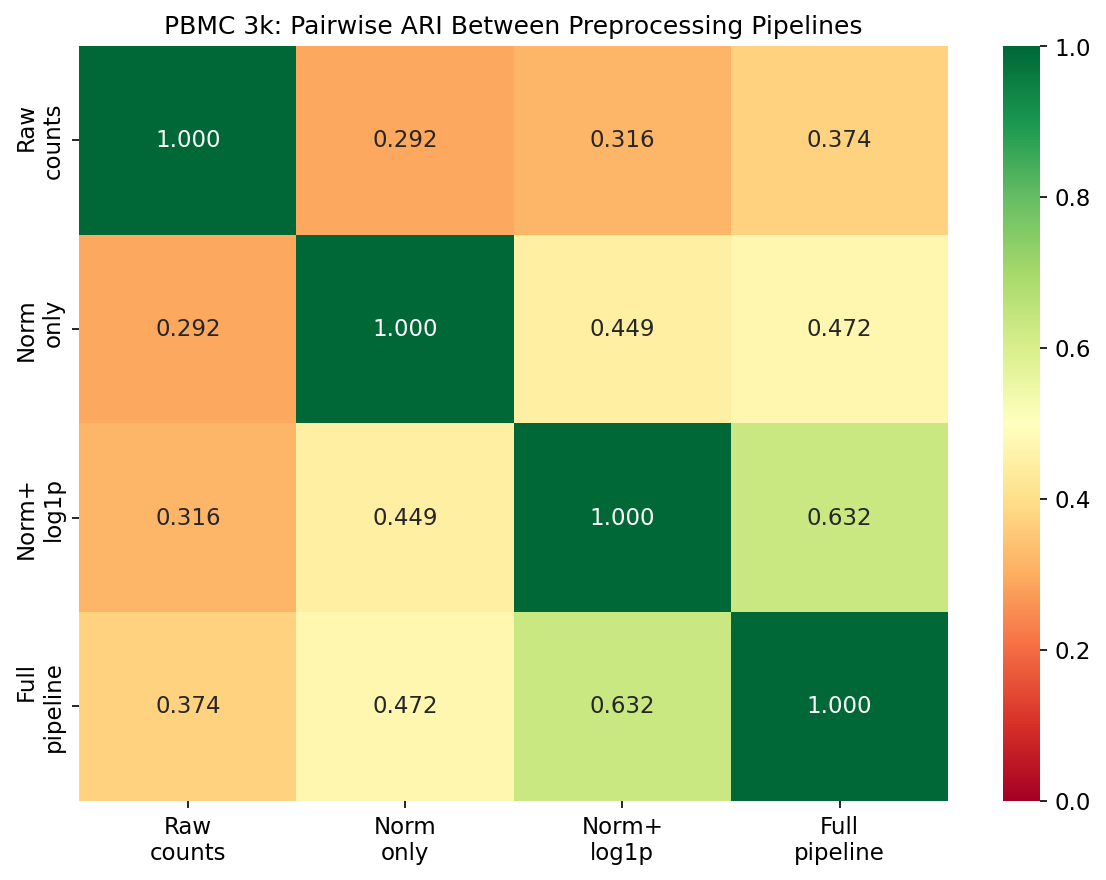

Figure saved: figures/08_preprocessing_pairwise_ari_heatmap_pbmc.png

=== Preprocessing Sensitivity Summary ===
BC ARI range: 0.491 to 0.730
Wine ARI range: 0.371 to 0.897
PBMC ARI range: 0.354 to 0.633
BC min pairwise ARI: 0.496
Wine min pairwise ARI: 0.354
PBMC min pairwise ARI: 0.292


In [6]:
SCALERS = {
    'No scaling (raw)': None,
    'StandardScaler (z-score)': StandardScaler(),
    'MinMaxScaler [0,1]': MinMaxScaler(),
    'RobustScaler (IQR)': RobustScaler(),
}

# For PBMC: biologically motivated pipelines
# Load raw PBMC for preprocessing comparison
print("Loading raw PBMC 3k for preprocessing sensitivity...")
adata_raw = sc.datasets.pbmc3k()
sc.pp.filter_cells(adata_raw, min_genes=200)
sc.pp.filter_genes(adata_raw, min_cells=3)
# Keep only cells that are in the processed dataset
common_cells = adata_raw.obs_names.intersection(adata.obs_names)
adata_raw = adata_raw[common_cells]
y_pbmc_raw = adata.obs.loc[common_cells, 'louvain'].cat.codes.values

PBMC_PIPELINES = {}

# Pipeline 1: Raw counts (just filtered, no normalisation)
X_raw_counts = adata_raw.X.toarray() if scipy.sparse.issparse(adata_raw.X) else np.array(adata_raw.X)
# Clip to 2000 HVGs using variance as proxy
gene_vars = np.var(X_raw_counts, axis=0)
top_genes = np.argsort(gene_vars)[-2000:]
PBMC_PIPELINES['Raw counts (top 2000 var genes)'] = X_raw_counts[:, top_genes]

# Pipeline 2: Normalised only
X_norm = X_raw_counts.copy().astype(float)
row_sums = X_norm.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
X_norm = X_norm / row_sums * 1e4
PBMC_PIPELINES['Normalised only (no log)'] = X_norm[:, top_genes]

# Pipeline 3: Normalised + log1p
X_log = np.log1p(X_norm)
PBMC_PIPELINES['Normalised + log1p'] = X_log[:, top_genes]

# Pipeline 4: Full standard pipeline (matches scanpy output)
X_full = X_log[:, top_genes].copy()
X_full = StandardScaler().fit_transform(X_full)
X_full = np.clip(X_full, -10, 10)
PBMC_PIPELINES['Normalised + log1p + scaled'] = X_full

def preprocessing_sensitivity(X_raw, y_true, k, dataset_name, scalers=None):
    """
    Apply each scaler/pipeline, cluster, compare against ground truth and each other.
    Pairwise ARI between scaler combinations reveals whether preprocessing choice
    is materially affecting conclusions.
    """
    if scalers is None:
        scalers = SCALERS
    results = {}
    for name, scaler in scalers.items():
        if scaler is None:
            X_proc = X_raw.values if hasattr(X_raw, 'values') else X_raw
        else:
            if isinstance(scaler, np.ndarray):
                X_proc = scaler
            else:
                X_proc = scaler.fit_transform(X_raw)
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = km.fit_predict(X_proc)
        ari_gt = adjusted_rand_score(y_true, labels)
        sil = silhouette_score(X_proc, labels, sample_size=min(1000, len(labels)))
        results[name] = {'labels': labels, 'ari_vs_ground_truth': ari_gt, 'silhouette': sil, 'X_scaled': X_proc}
    
    scaler_names = list(results.keys())
    pairwise = np.zeros((len(scaler_names), len(scaler_names)))
    for i, n1 in enumerate(scaler_names):
        for j, n2 in enumerate(scaler_names):
            pairwise[i, j] = adjusted_rand_score(results[n1]['labels'], results[n2]['labels'])
    return results, pairwise, scaler_names

print("Running preprocessing sensitivity: Breast Cancer...")
results_prep_bc, pairwise_bc, scaler_names = preprocessing_sensitivity(X_bc, y_bc, k=2, dataset_name='Breast Cancer')
print("Running preprocessing sensitivity: Wine...")
results_prep_wine, pairwise_wine, _ = preprocessing_sensitivity(X_wine, y_wine, k=3, dataset_name='Wine')
print("Running preprocessing sensitivity: PBMC 3k...")
pbmc_pipeline_dict = {name: None for name in PBMC_PIPELINES}  # None signals use pre-built matrix
results_prep_pbmc = {}
for name, X_proc in PBMC_PIPELINES.items():
    km = KMeans(n_clusters=8, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_proc)
    ari_gt = adjusted_rand_score(y_pbmc_raw, labels)
    sil = silhouette_score(X_proc, labels, sample_size=min(1000, len(labels)))
    results_prep_pbmc[name] = {'labels': labels, 'ari_vs_ground_truth': ari_gt, 'silhouette': sil}
    print(f"  {name}: ARI={ari_gt:.3f}, Sil={sil:.3f}")

pbmc_pipeline_names = list(PBMC_PIPELINES.keys())
pairwise_pbmc = np.zeros((len(pbmc_pipeline_names), len(pbmc_pipeline_names)))
for i, n1 in enumerate(pbmc_pipeline_names):
    for j, n2 in enumerate(pbmc_pipeline_names):
        pairwise_pbmc[i, j] = adjusted_rand_score(results_prep_pbmc[n1]['labels'], results_prep_pbmc[n2]['labels'])

# Plot ARI vs ground truth for all three datasets
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Preprocessing Sensitivity: ARI vs Ground Truth', fontsize=14)

for ax, results, names, title, color in [
    (axes[0], results_prep_bc, scaler_names, 'Breast Cancer (k=2)', 'steelblue'),
    (axes[1], results_prep_wine, scaler_names, 'Wine (k=3)', 'coral'),
    (axes[2], results_prep_pbmc, pbmc_pipeline_names, 'PBMC 3k (k=8)', 'mediumseagreen'),
]:
    aris = [results[n]['ari_vs_ground_truth'] for n in names]
    x = np.arange(len(names))
    ax.bar(x, aris, color=color, alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace(' ', '\n') for n in names], fontsize=7)
    ax.set_ylabel('ARI vs Ground Truth')
    ax.set_title(title)
    ax.set_ylim(0, 1.1)
    for i, v in enumerate(aris):
        ax.text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('figures/06_preprocessing_ari_vs_groundtruth.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/06_preprocessing_ari_vs_groundtruth.png")

short_names = ['Raw', 'Standard', 'MinMax', 'Robust']
short_pbmc = ['Raw\ncounts', 'Norm\nonly', 'Norm+\nlog1p', 'Full\npipeline']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(pairwise_bc, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1,
            xticklabels=short_names, yticklabels=short_names, ax=axes[0])
axes[0].set_title('Breast Cancer: Pairwise ARI Between Scalers')
sns.heatmap(pairwise_wine, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1,
            xticklabels=short_names, yticklabels=short_names, ax=axes[1])
axes[1].set_title('Wine: Pairwise ARI Between Scalers')
plt.tight_layout()
plt.savefig('figures/07_preprocessing_pairwise_ari_heatmap_bc_wine.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/07_preprocessing_pairwise_ari_heatmap_bc_wine.png")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pairwise_pbmc, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1,
            xticklabels=short_pbmc, yticklabels=short_pbmc, ax=ax)
ax.set_title('PBMC 3k: Pairwise ARI Between Preprocessing Pipelines')
plt.tight_layout()
plt.savefig('figures/08_preprocessing_pairwise_ari_heatmap_pbmc.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/08_preprocessing_pairwise_ari_heatmap_pbmc.png")

print("\n=== Preprocessing Sensitivity Summary ===")
bc_aris = [results_prep_bc[n]['ari_vs_ground_truth'] for n in scaler_names]
wine_aris = [results_prep_wine[n]['ari_vs_ground_truth'] for n in scaler_names]
pbmc_aris = [results_prep_pbmc[n]['ari_vs_ground_truth'] for n in pbmc_pipeline_names]
print(f"BC ARI range: {min(bc_aris):.3f} to {max(bc_aris):.3f}")
print(f"Wine ARI range: {min(wine_aris):.3f} to {max(wine_aris):.3f}")
print(f"PBMC ARI range: {min(pbmc_aris):.3f} to {max(pbmc_aris):.3f}")
print(f"BC min pairwise ARI: {pairwise_bc[np.tril_indices_from(pairwise_bc, k=-1)].min():.3f}")
print(f"Wine min pairwise ARI: {pairwise_wine[np.tril_indices_from(pairwise_wine, k=-1)].min():.3f}")
print(f"PBMC min pairwise ARI: {pairwise_pbmc[np.tril_indices_from(pairwise_pbmc, k=-1)].min():.3f}")

## Dimensionality Reduction

### The curse of dimensionality, PCA, and UMAP

High-dimensional spaces behave counterintuitively. As dimensionality increases, Euclidean distances between randomly distributed points become more similar to each other (the ratio of maximum to minimum pairwise distance approaches 1). This means that in high-dimensional spaces, "nearest neighbour" queries become less meaningful because all points are approximately equidistant. Clustering algorithms that depend on distance (including KMeans) are therefore expected to degrade in very high dimensions.

The Breast Cancer dataset (30 features) and Wine dataset (13 features) are in this sense low-dimensional enough that KMeans works directly on the scaled data. The PBMC dataset (1838 features after HVG selection) is a genuinely high-dimensional problem where dimensionality reduction is not optional but necessary.

**PCA (Principal Component Analysis):** Finds orthogonal linear combinations of features that capture the maximum variance in descending order. PCA-2 retains only the two directions of greatest variance (useful for visualisation); PCA-10 retains 10 components; PCA-95pct retains enough components to explain 95% of variance. PCA preserves global structure (large-scale relationships between groups) but may discard local structure and non-linear relationships. It is deterministic and computationally cheap.

**UMAP (Uniform Manifold Approximation and Projection):** A non-linear dimensionality reduction method that preserves local neighbourhood structure. UMAP is optimised for visualisation (typically projected to 2 dimensions) and can reveal non-linear cluster structure that PCA cannot. However, UMAP is stochastic (different random seeds can give topologically different layouts), it distorts global distances (the distance between clusters in a UMAP plot is not interpretable), and it has several hyperparameters (n_neighbors, min_dist) that can substantially change the output.

**PBMC standard pipeline note:** In the scRNA-seq field, the standard analysis workflow is PCA-50 (or similar) followed by UMAP for visualisation and Louvain/Leiden graph clustering on the PCA-50 neighbourhood graph. This represents the current consensus approach for this data type. The Louvain labels used as PBMC "ground truth" were themselves produced using PCA-50 as the input representation, so comparing KMeans-on-PCA-50 against those labels is measuring agreement between two methods that share the same input representation.

**ARI vs stability scatter:** Plotting ARI (accuracy relative to ground truth) against bootstrap stability for each dimensionality reduction method reveals four qualitatively different situations:
- High ARI, high stability: the method reliably recovers the ground truth structure. Best case.
- High ARI, low stability: the method occasionally recovers ground truth but is unreliable. Any single result may be a lucky draw.
- Low ARI, high stability: the method consistently finds a structure that differs from ground truth. Stable but wrong (relative to the reference labels).
- Low ARI, low stability: the method is both inaccurate and unreliable. No useful information.

### Dimensionality reduction choices for PBMC: what is and is not tested

See the Key Methodological Decisions section for the full argument. In brief: PCA-10, PCA-50, and UMAP-2 are tested as independent alternatives, each applied directly to the full 1838-dimensional scaled HVG space. This is not a combined PCA-50+UMAP pipeline; it is a comparison of three separate reductions. The reason PCA-10 achieves higher ARI than PCA-50 despite the reference using 50 components is discussed in the Key Methodological Decisions section.


Dimensionality reduction: Breast Cancer...
  No reduction...


    ARI=0.654, Stability=0.953+-0.049
  PCA-2...


    ARI=0.659, Stability=0.961+-0.054
  PCA-10...


    ARI=0.671, Stability=0.953+-0.050
  PCA-95pct...


    ARI=0.671, Stability=0.953+-0.050
  UMAP-2...


...

    ARI=0.774, Stability=1.000+-0.000

Dimensionality reduction: PBMC 3k...
  No reduction (1838 HVGs)...


    ARI=0.779, Stability=0.782+-0.101
  PCA-10...


    ARI=0.898, Stability=0.836+-0.138
  PCA-50...


    ARI=0.652, Stability=0.820+-0.121
  UMAP-2...


    ARI=0.116, Stability=0.931+-0.030


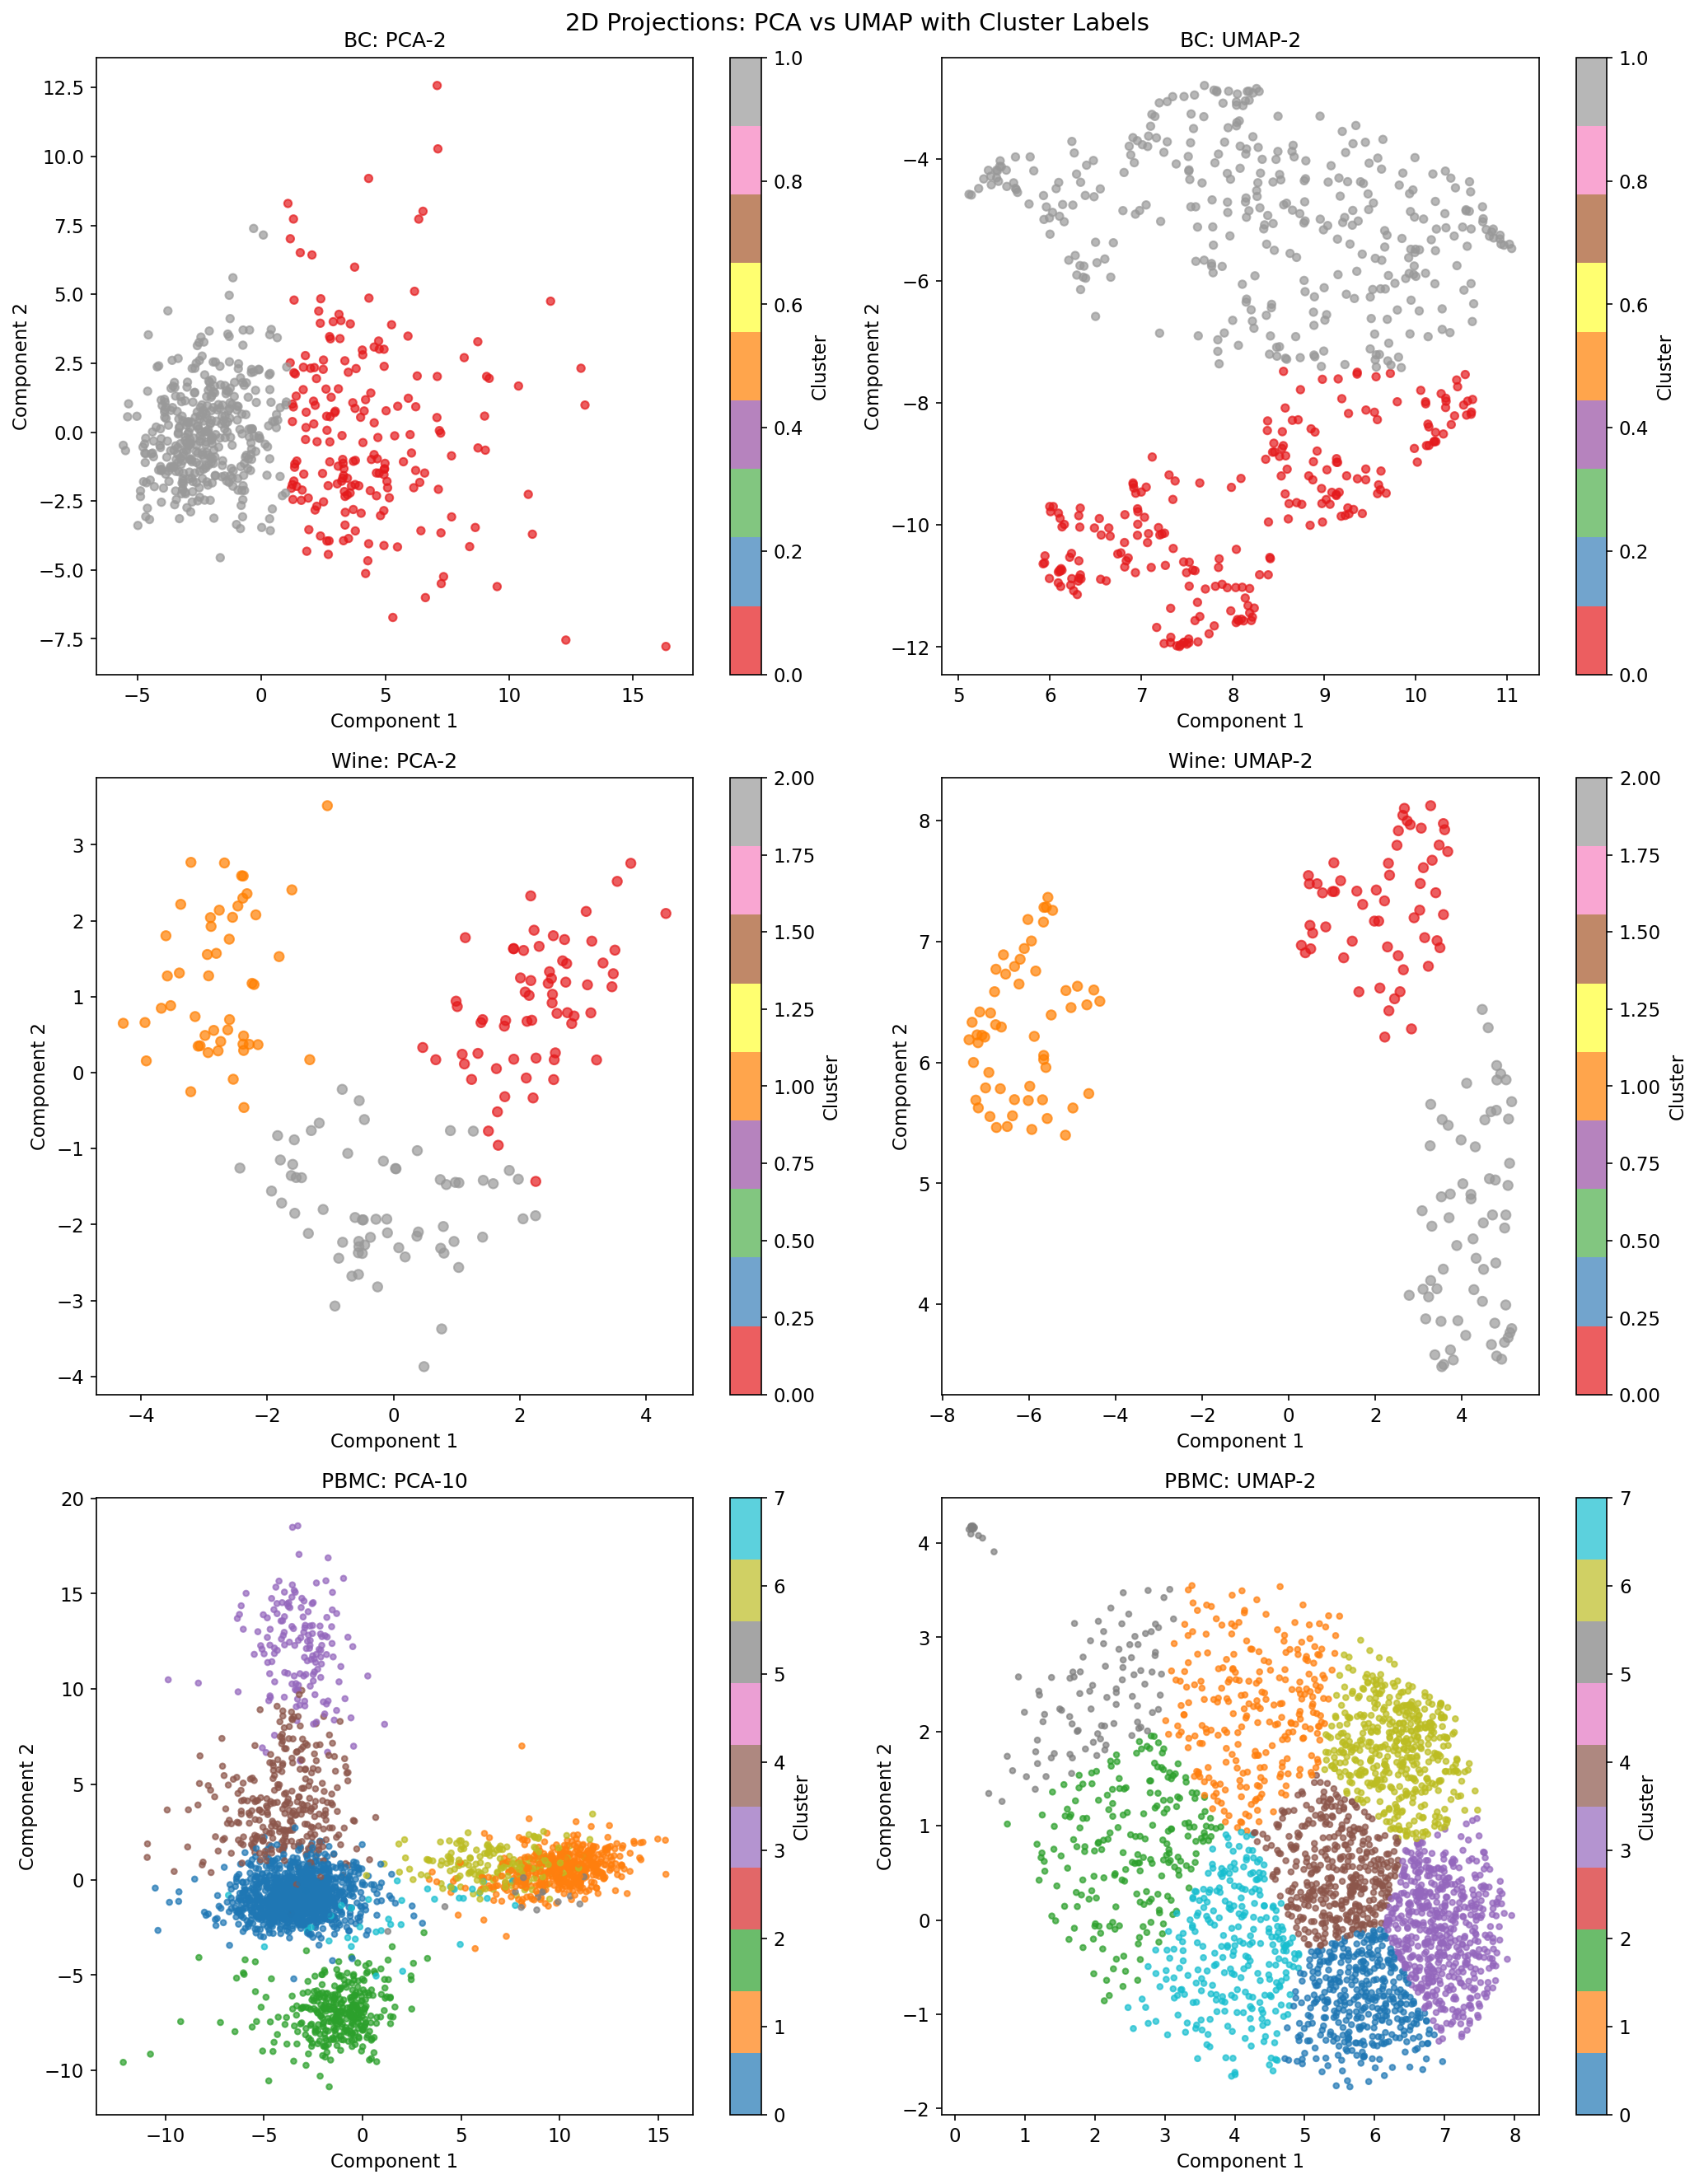

Figure saved: figures/09_dimred_projections.png


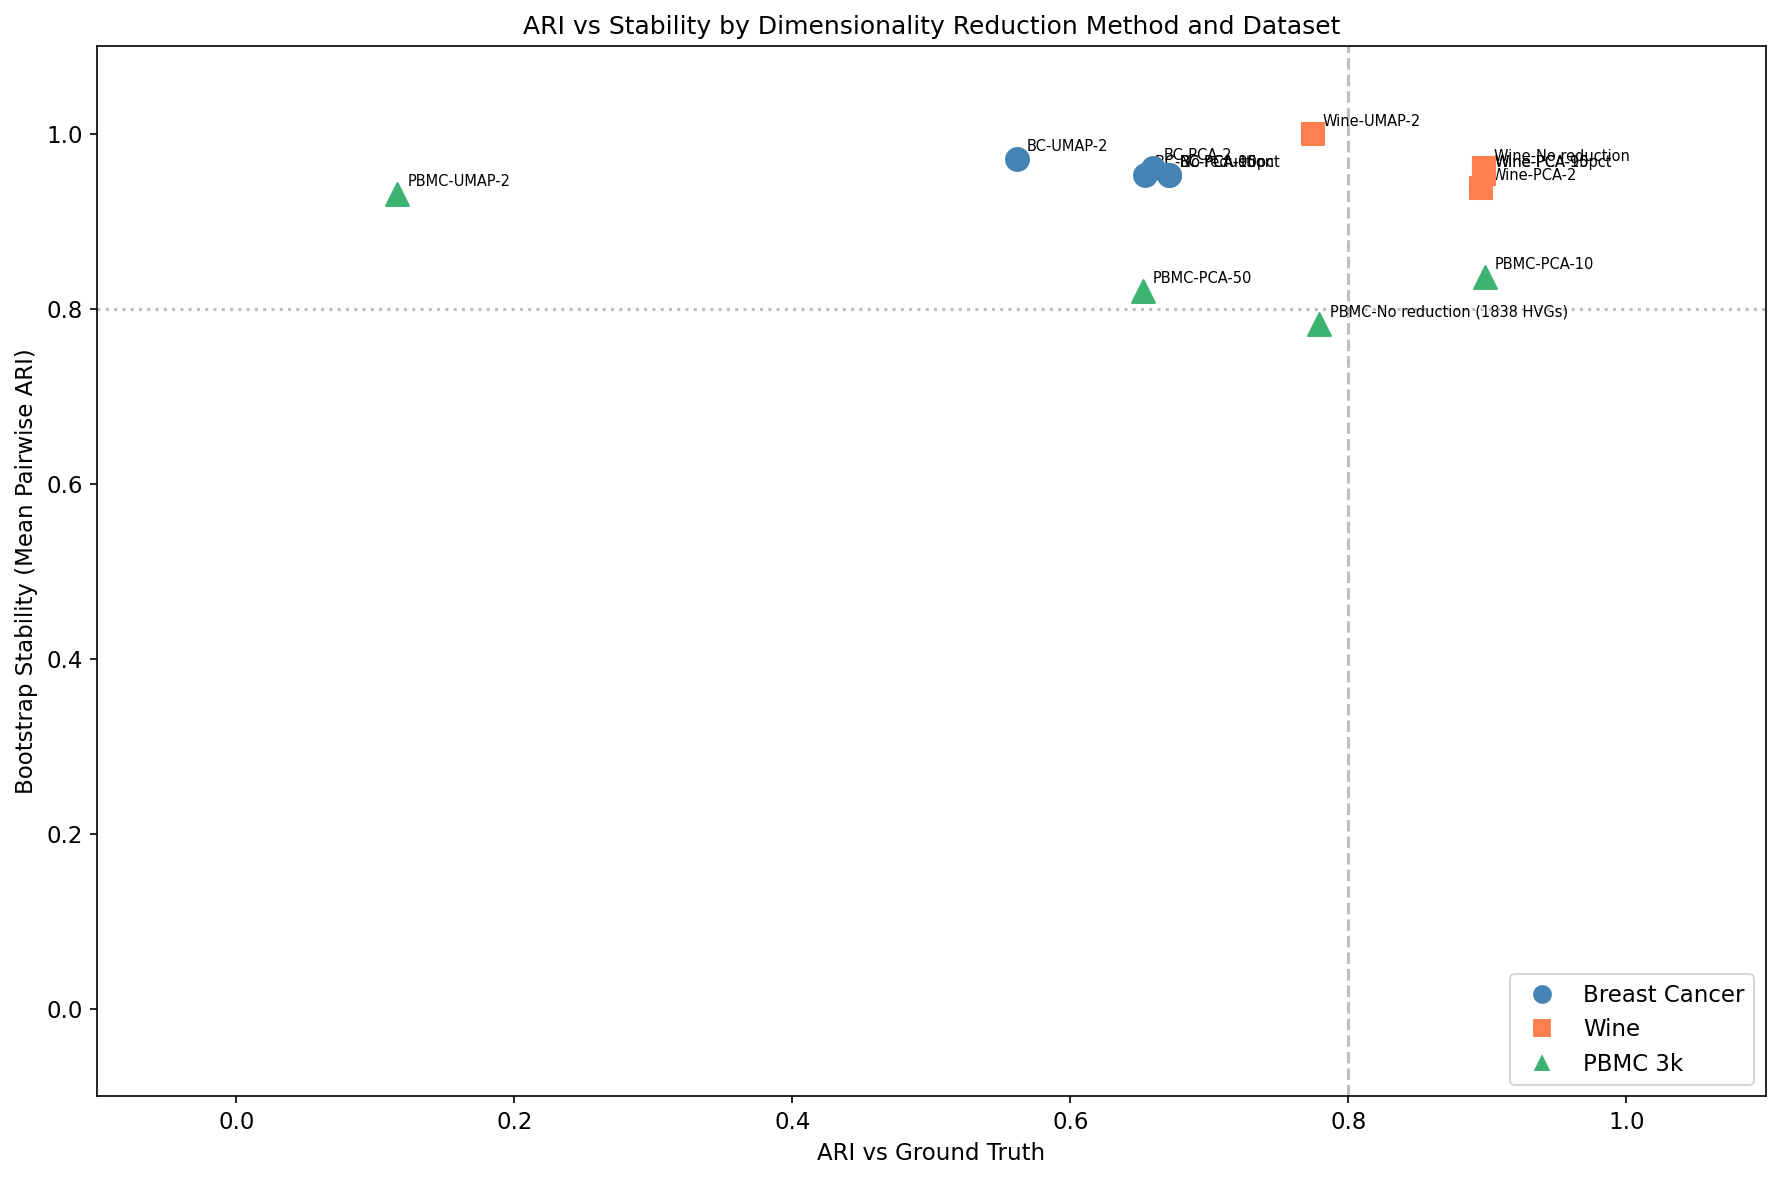

Figure saved: figures/10_ari_vs_stability_scatter.png


In [7]:
DIM_REDUCTIONS = {
    'No reduction': None,
    'PCA-2': PCA(n_components=2, random_state=RANDOM_STATE),
    'PCA-10': PCA(n_components=10, random_state=RANDOM_STATE),
    'PCA-95pct': PCA(n_components=0.95, random_state=RANDOM_STATE),
    'UMAP-2': umap.UMAP(n_components=2, random_state=RANDOM_STATE),
}

# PBMC-specific reductions (PCA-50 is standard before UMAP in scRNA-seq)
PBMC_DIM_REDUCTIONS = {
    'No reduction (1838 HVGs)': None,
    'PCA-10': PCA(n_components=10, random_state=RANDOM_STATE),
    'PCA-50': PCA(n_components=50, random_state=RANDOM_STATE),
    'UMAP-2': umap.UMAP(n_components=2, random_state=RANDOM_STATE),
}

def dimred_sensitivity(X_scaled, y_true, k, dataset_name, reductions=None):
    """
    Apply dimensionality reduction then cluster.
    Returns ARI vs ground truth and bootstrap stability for each method.
    UMAP is non-deterministic across hardware even with a fixed seed.
    """
    if reductions is None:
        reductions = DIM_REDUCTIONS
    results = {}
    for name, reducer in reductions.items():
        print(f"  {name}...")
        if reducer is None:
            X_reduced = X_scaled
        else:
            X_reduced = reducer.fit_transform(X_scaled)
        stability = bootstrap_stability(X_reduced, k, n_iterations=30, subsample_fraction=0.8)
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = km.fit_predict(X_reduced)
        ari_gt = adjusted_rand_score(y_true, labels)
        results[name] = {
            'ari_vs_ground_truth': ari_gt,
            'bootstrap_mean_ari': stability['mean_ari'],
            'bootstrap_std_ari': stability['std_ari'],
            'n_dims': X_reduced.shape[1],
            'labels': labels,
            'X_reduced': X_reduced
        }
        print(f"    ARI={ari_gt:.3f}, Stability={stability['mean_ari']:.3f}+-{stability['std_ari']:.3f}")
    return results

print("Dimensionality reduction: Breast Cancer...")
dimred_bc = dimred_sensitivity(X_bc_scaled, y_bc, k=2, dataset_name='Breast Cancer')
print("\nDimensionality reduction: Wine...")
dimred_wine = dimred_sensitivity(X_wine_scaled, y_wine, k=3, dataset_name='Wine')
print("\nDimensionality reduction: PBMC 3k...")
dimred_pbmc = dimred_sensitivity(X_pbmc_scaled, y_pbmc, k=8, dataset_name='PBMC 3k', reductions=PBMC_DIM_REDUCTIONS)

# 2D projections for all three datasets
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
fig.suptitle('2D Projections: PCA vs UMAP with Cluster Labels', fontsize=14)

# BC
for col_idx, key in enumerate(['PCA-2', 'UMAP-2']):
    X_2d = dimred_bc[key]['X_reduced']
    labels = dimred_bc[key]['labels']
    sc_plot = axes[0, col_idx].scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='Set1', alpha=0.7, s=20)
    axes[0, col_idx].set_title(f"BC: {key}")
    axes[0, col_idx].set_xlabel('Component 1'); axes[0, col_idx].set_ylabel('Component 2')
    plt.colorbar(sc_plot, ax=axes[0, col_idx], label='Cluster')

# Wine
for col_idx, key in enumerate(['PCA-2', 'UMAP-2']):
    X_2d = dimred_wine[key]['X_reduced']
    labels = dimred_wine[key]['labels']
    sc_plot = axes[1, col_idx].scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='Set1', alpha=0.7, s=30)
    axes[1, col_idx].set_title(f"Wine: {key}")
    axes[1, col_idx].set_xlabel('Component 1'); axes[1, col_idx].set_ylabel('Component 2')
    plt.colorbar(sc_plot, ax=axes[1, col_idx], label='Cluster')

# PBMC
for col_idx, key in enumerate(['PCA-10', 'UMAP-2']):
    X_2d = dimred_pbmc[key]['X_reduced']
    if X_2d.shape[1] > 2:
        X_2d = X_2d[:, :2]
    labels = dimred_pbmc[key]['labels']
    sc_plot = axes[2, col_idx].scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab10', alpha=0.7, s=10)
    axes[2, col_idx].set_title(f"PBMC: {key}")
    axes[2, col_idx].set_xlabel('Component 1'); axes[2, col_idx].set_ylabel('Component 2')
    plt.colorbar(sc_plot, ax=axes[2, col_idx], label='Cluster')

plt.tight_layout()
plt.savefig('figures/09_dimred_projections.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/09_dimred_projections.png")

# ARI vs stability scatter
fig, ax = plt.subplots(figsize=(12, 8))
dataset_config = [
    ('BC', dimred_bc, 'steelblue', 'o'),
    ('Wine', dimred_wine, 'coral', 's'),
    ('PBMC', dimred_pbmc, 'mediumseagreen', '^'),
]
for ds_name, dimred_results, color, marker in dataset_config:
    for method, res in dimred_results.items():
        ax.scatter(res['ari_vs_ground_truth'], res['bootstrap_mean_ari'],
                   color=color, marker=marker, s=120, zorder=5)
        ax.annotate(f"{ds_name}-{method}", (res['ari_vs_ground_truth'], res['bootstrap_mean_ari']),
                    textcoords='offset points', xytext=(5, 4), fontsize=7)

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='steelblue', markersize=10, label='Breast Cancer'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='coral', markersize=10, label='Wine'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='mediumseagreen', markersize=10, label='PBMC 3k'),
]
ax.legend(handles=legend_elements, loc='lower right')
ax.set_xlabel('ARI vs Ground Truth')
ax.set_ylabel('Bootstrap Stability (Mean Pairwise ARI)')
ax.set_title('ARI vs Stability by Dimensionality Reduction Method and Dataset')
ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.1, 1.1)
ax.axhline(0.8, color='gray', linestyle=':', alpha=0.5)
ax.axvline(0.8, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('figures/10_ari_vs_stability_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/10_ari_vs_stability_scatter.png")

## K Sensitivity

### What happens when internal metrics disagree with the ground truth k

One of the most common practical questions in clustering is: how many clusters should I use? The experiments below vary k and measure three quantities: ARI versus ground truth, silhouette score (internal metric), and bootstrap stability.

**When internal metrics agree with ground truth k:** The silhouette score peaks at the same k that maximises ARI. This is the ideal scenario. It means the cluster structure that the data geometry prefers corresponds to the biologically or scientifically meaningful partition. For the Breast Cancer dataset (2 classes) and Wine dataset (3 classes), this is worth checking explicitly.

**When internal metrics disagree with ground truth k:** The silhouette peaks at a different k than the ground truth. This can happen for several reasons:
- The ground truth classes have unequal sizes (silhouette favours equal-sized clusters)
- The ground truth classes have non-convex shapes (silhouette favours compact spherical clusters)
- The data contains sub-structure within each ground truth class
- The ground truth k is not the geometrically most natural number of partitions

When internal metrics disagree with ground truth, the correct response is not to override the ground truth but to investigate why. The silhouette score tells you about the geometry of the data; the ground truth tells you about the science. They answer different questions.

**Stability across k:** Bootstrap stability typically decreases for large k (more clusters are harder to recover consistently) and for k=2 (trivially stable, hard to get wrong). The relationship between stability and k reveals how robust a particular cluster count is.

**PBMC k note:** The "true" k=8 for PBMC is the number of cell type annotations produced by one specific Louvain run. This is not a ground truth in the same sense as the breast cancer diagnosis labels. A silhouette analysis that prefers k=5 or k=12 is not wrong. It is finding a different partition of the data, and whether that partition is more or less biologically meaningful than the Louvain-8 partition is a scientific question that cannot be resolved by a metric alone.

K sensitivity: Breast Cancer...
  k=2...


  k=3...


  k=4...


  k=5...


  k=6...


...

  k=8...


  k=9...


  k=10...


  k=11...


  k=12...


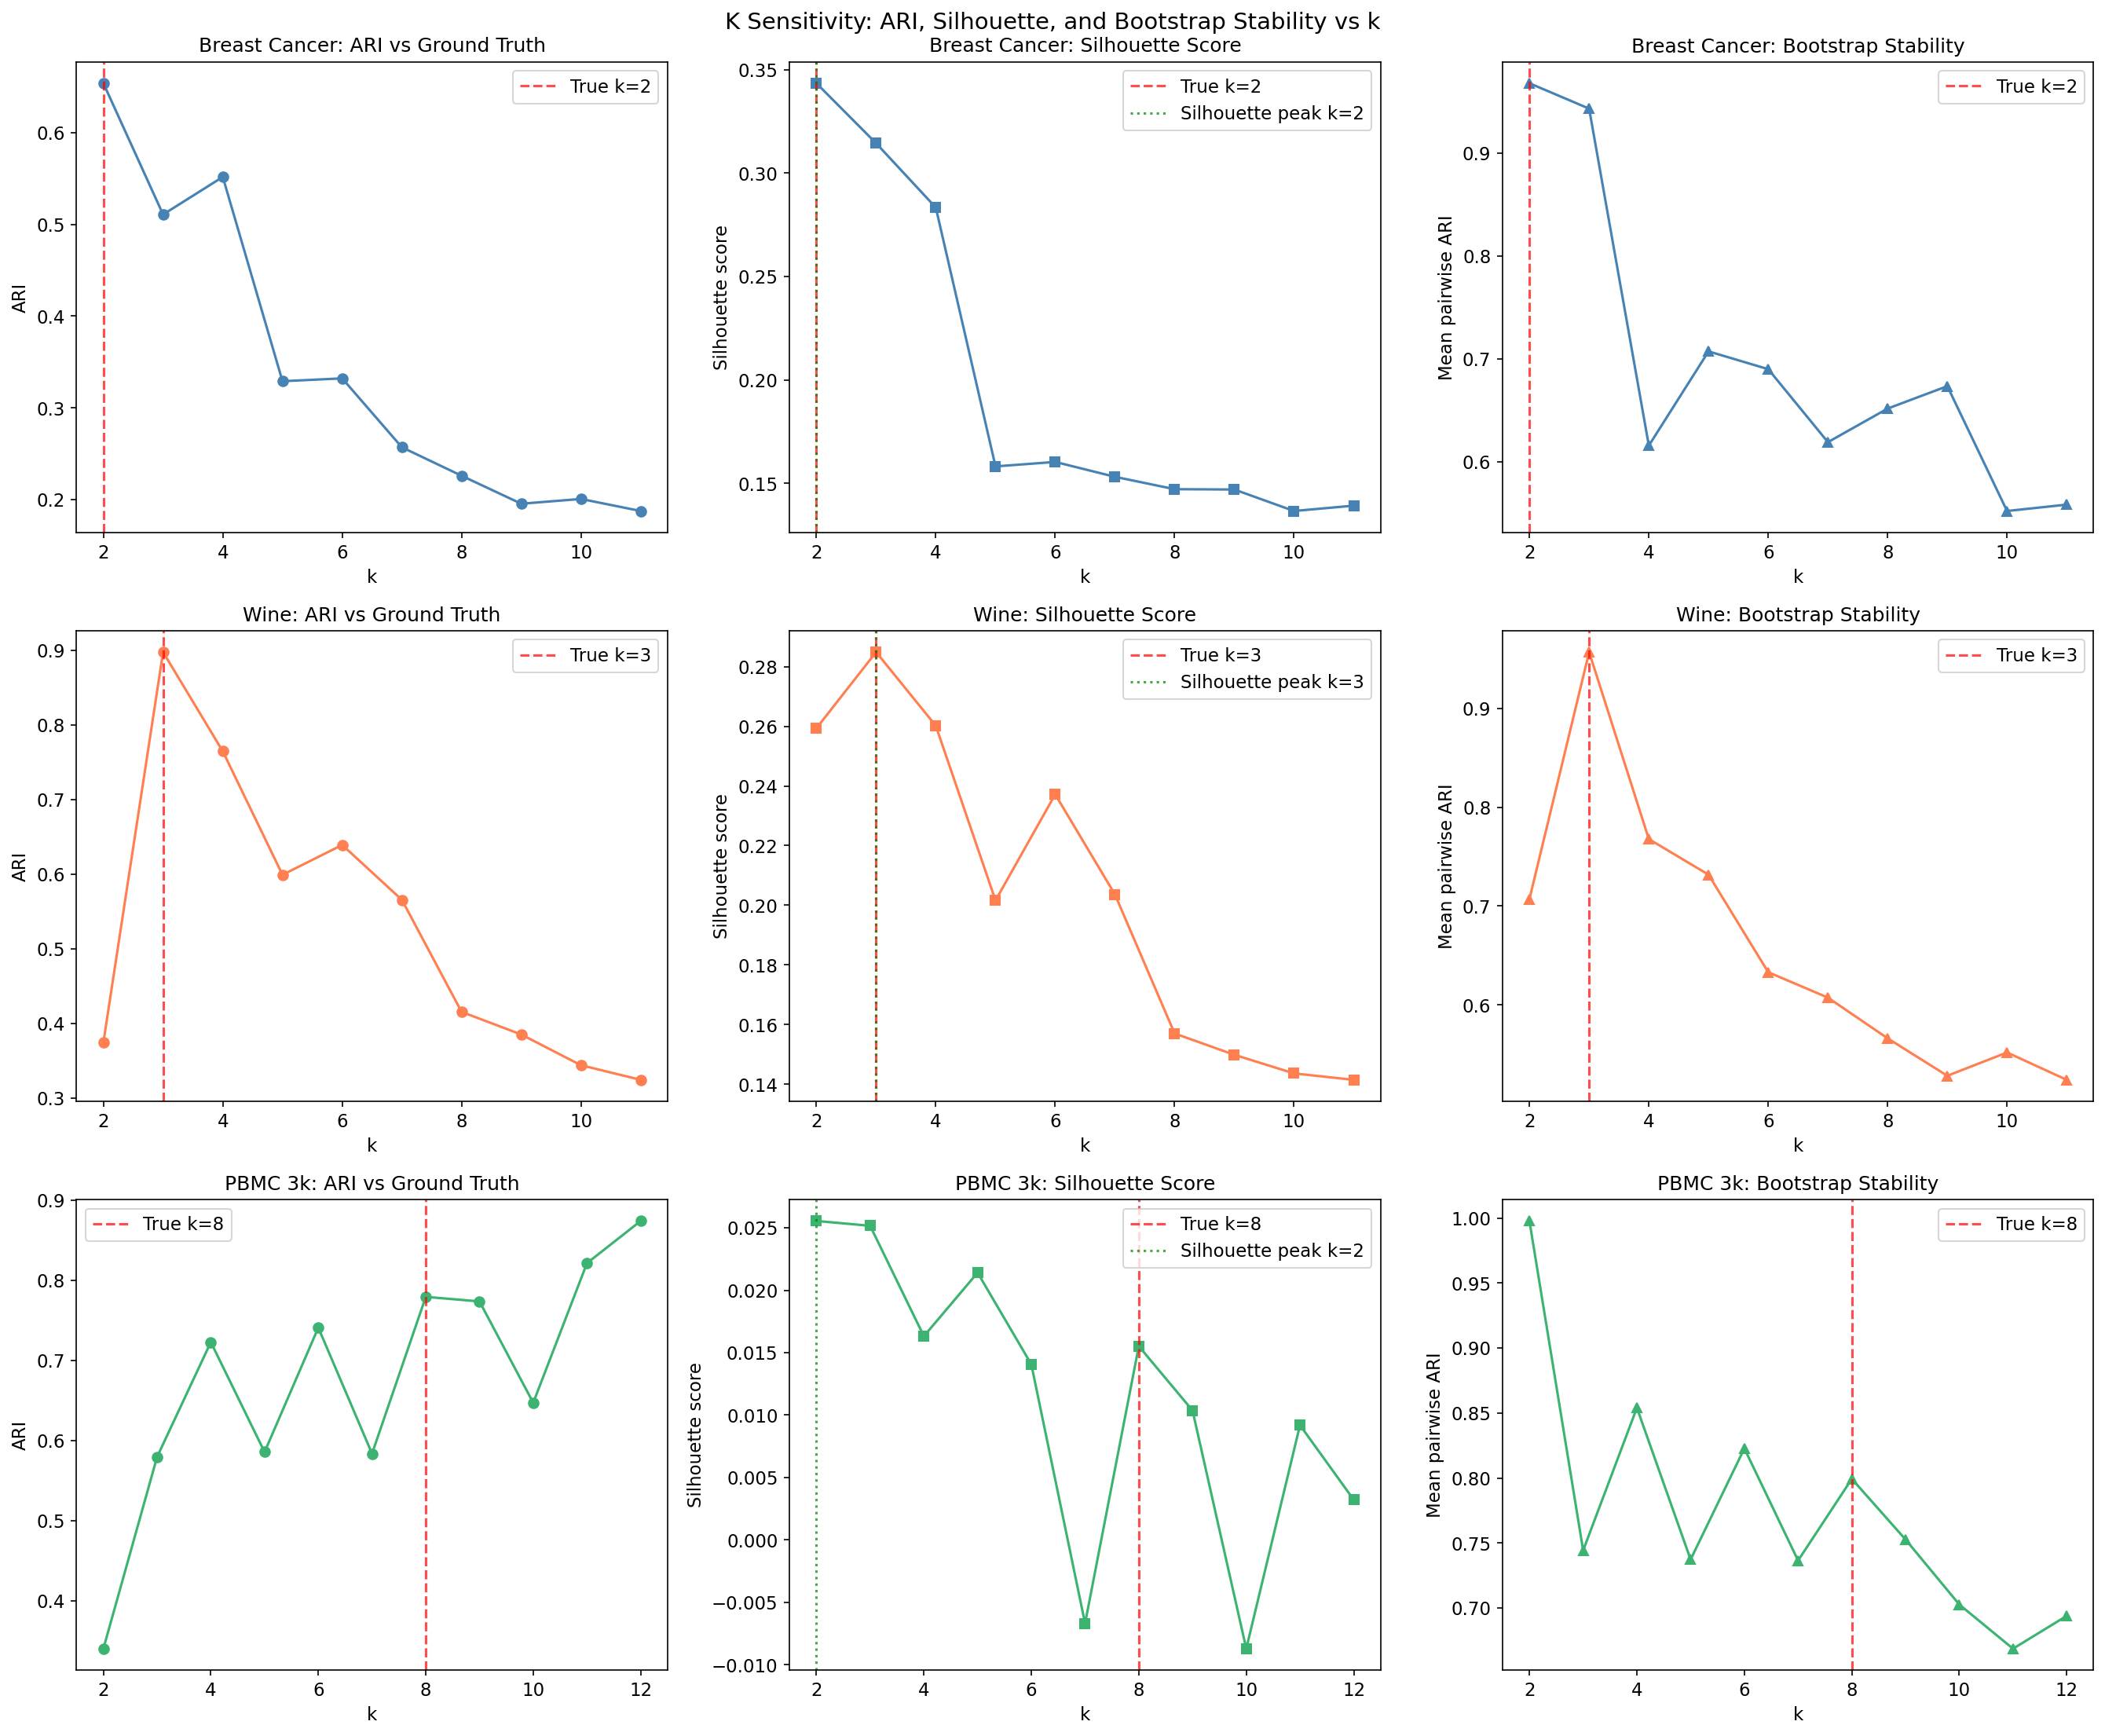

Figure saved: figures/11_k_sensitivity_threepanel.png

=== K Sensitivity Summary ===
Breast Cancer: True k=2, Silhouette peaks at k=2, ARI peaks at k=2
Wine: True k=3, Silhouette peaks at k=3, ARI peaks at k=3
PBMC 3k: True k=8, Silhouette peaks at k=2, ARI peaks at k=12


In [8]:
def k_sensitivity(X_scaled, y_true, k_true, dataset_name, k_range=range(2, 12)):
    """
    Vary k, measure ARI, silhouette, and bootstrap stability at each value.
    """
    results = []
    for k in k_range:
        print(f"  k={k}...")
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = km.fit_predict(X_scaled)
        ari = adjusted_rand_score(y_true, labels)
        sil = silhouette_score(X_scaled, labels, sample_size=min(1000, len(labels))) if k > 1 else np.nan
        stability = bootstrap_stability(X_scaled, k, n_iterations=20)
        results.append({'k': k, 'ari_vs_ground_truth': ari, 'silhouette': sil, 'bootstrap_stability': stability['mean_ari']})
    return pd.DataFrame(results)

print("K sensitivity: Breast Cancer...")
k_sens_bc = k_sensitivity(X_bc_scaled, y_bc, k_true=2, dataset_name='Breast Cancer')
print("K sensitivity: Wine...")
k_sens_wine = k_sensitivity(X_wine_scaled, y_wine, k_true=3, dataset_name='Wine')
print("K sensitivity: PBMC 3k (k=2 to 12)...")
k_sens_pbmc = k_sensitivity(X_pbmc_scaled, y_pbmc, k_true=8, dataset_name='PBMC 3k', k_range=range(2, 13))

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('K Sensitivity: ARI, Silhouette, and Bootstrap Stability vs k', fontsize=14)

for row, (df, name, k_true, color) in enumerate([
    (k_sens_bc, 'Breast Cancer', 2, 'steelblue'),
    (k_sens_wine, 'Wine', 3, 'coral'),
    (k_sens_pbmc, 'PBMC 3k', 8, 'mediumseagreen'),
]):
    axes[row, 0].plot(df['k'], df['ari_vs_ground_truth'], color=color, marker='o')
    axes[row, 0].axvline(k_true, color='red', linestyle='--', alpha=0.7, label=f'True k={k_true}')
    axes[row, 0].set_title(f'{name}: ARI vs Ground Truth')
    axes[row, 0].set_xlabel('k'); axes[row, 0].set_ylabel('ARI')
    axes[row, 0].legend()

    axes[row, 1].plot(df['k'], df['silhouette'], color=color, marker='s')
    axes[row, 1].axvline(k_true, color='red', linestyle='--', alpha=0.7, label=f'True k={k_true}')
    sil_peak_k = df.loc[df['silhouette'].idxmax(), 'k']
    axes[row, 1].axvline(sil_peak_k, color='green', linestyle=':', alpha=0.7, label=f'Silhouette peak k={sil_peak_k}')
    axes[row, 1].set_title(f'{name}: Silhouette Score')
    axes[row, 1].set_xlabel('k'); axes[row, 1].set_ylabel('Silhouette score')
    axes[row, 1].legend()

    axes[row, 2].plot(df['k'], df['bootstrap_stability'], color=color, marker='^')
    axes[row, 2].axvline(k_true, color='red', linestyle='--', alpha=0.7, label=f'True k={k_true}')
    axes[row, 2].set_title(f'{name}: Bootstrap Stability')
    axes[row, 2].set_xlabel('k'); axes[row, 2].set_ylabel('Mean pairwise ARI')
    axes[row, 2].legend()

plt.tight_layout()
plt.savefig('figures/11_k_sensitivity_threepanel.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/11_k_sensitivity_threepanel.png")

print("\n=== K Sensitivity Summary ===")
for df, name, k_true in [(k_sens_bc, 'Breast Cancer', 2), (k_sens_wine, 'Wine', 3), (k_sens_pbmc, 'PBMC 3k', 8)]:
    sil_peak = df.loc[df['silhouette'].idxmax(), 'k']
    ari_peak = df.loc[df['ari_vs_ground_truth'].idxmax(), 'k']
    print(f"{name}: True k={k_true}, Silhouette peaks at k={sil_peak}, ARI peaks at k={ari_peak}")

## Algorithm Sensitivity

### What divergence between algorithms reveals

Different clustering algorithms make different assumptions about cluster shape, size, and density. Comparing their outputs on the same data reveals which properties of the cluster structure are robust (all algorithms agree) and which are algorithm-dependent artefacts (algorithms disagree).

**KMeans (k-means++ initialisation):** Minimises within-cluster sum of squares. Assumes clusters are convex, roughly spherical, and of similar size. The k-means++ initialisation heuristic selects initial centroids spread across the data space, reducing sensitivity to unlucky random initialisation. This is generally the default and recommended KMeans initialisation.

**KMeans (random initialisation):** Same objective but initialises centroids uniformly at random. This is more sensitive to unlucky draws and may require more restarts (n_init) to find a good solution. Comparing k-means++ against random initialisation within KMeans isolates the effect of the initialisation strategy from the effect of the objective function.

**Agglomerative clustering (Ward linkage):** Bottom-up hierarchical clustering that merges clusters to minimise the increase in total within-cluster variance. Ward linkage tends to produce compact, equal-sized clusters. It is deterministic and does not require specifying k upfront (k is chosen by cutting the dendrogram). When Ward and KMeans agree, it is strong evidence of compact, separable cluster structure.

**Agglomerative clustering (complete linkage):** Merges based on the maximum pairwise distance between clusters. This tends to produce compact, equal-diameter clusters and is sensitive to outliers. Complete linkage often disagrees with Ward when clusters have unequal densities.

**Agglomerative clustering (average linkage):** Merges based on average pairwise distance between clusters. This is a compromise between single linkage (which creates chaining artefacts) and complete linkage. Average linkage is less sensitive to outliers than complete linkage.

**Interpretation:** If all five algorithms agree on the cluster assignments (high pairwise ARI across all pairs), the cluster structure is robust to algorithmic assumptions. If only KMeans variants agree with each other but not with agglomerative methods, or vice versa, the structure is algorithm-dependent and should be reported with explicit acknowledgment of algorithm sensitivity.

**PBMC caveat:** Ward linkage assumes compact, spherical clusters with roughly equal intra-cluster variance. Cell type boundaries in transcriptomic space are not necessarily spherical. Dendritic cells (37 cells) and Megakaryocytes (15 cells) are much smaller clusters than CD4 T cells (1144 cells). Hierarchical methods that assume similar cluster sizes or densities will struggle with this imbalance. Disagreement between Ward and KMeans for PBMC is therefore expected and biologically interpretable, not a sign of algorithmic failure.

Algorithm sensitivity: Breast Cancer...
  KMeans (k-means++): ARI=0.654
  KMeans (random init): ARI=0.654
  Agglomerative (ward): ARI=0.575
  Agglomerative (complete): ARI=0.005
  Agglomerative (average): ARI=0.007

Algorithm sensitivity: Wine...
  KMeans (k-means++): ARI=0.897


  KMeans (random init): ARI=0.897
  Agglomerative (ward): ARI=0.790
  Agglomerative (complete): ARI=0.577
  Agglomerative (average): ARI=-0.005

Algorithm sensitivity: PBMC 3k...


  KMeans (k-means++): ARI=0.779


  KMeans (random init): ARI=0.757


  Agglomerative (ward): ARI=0.706


  Agglomerative (complete): ARI=0.112


  Agglomerative (average): ARI=0.007


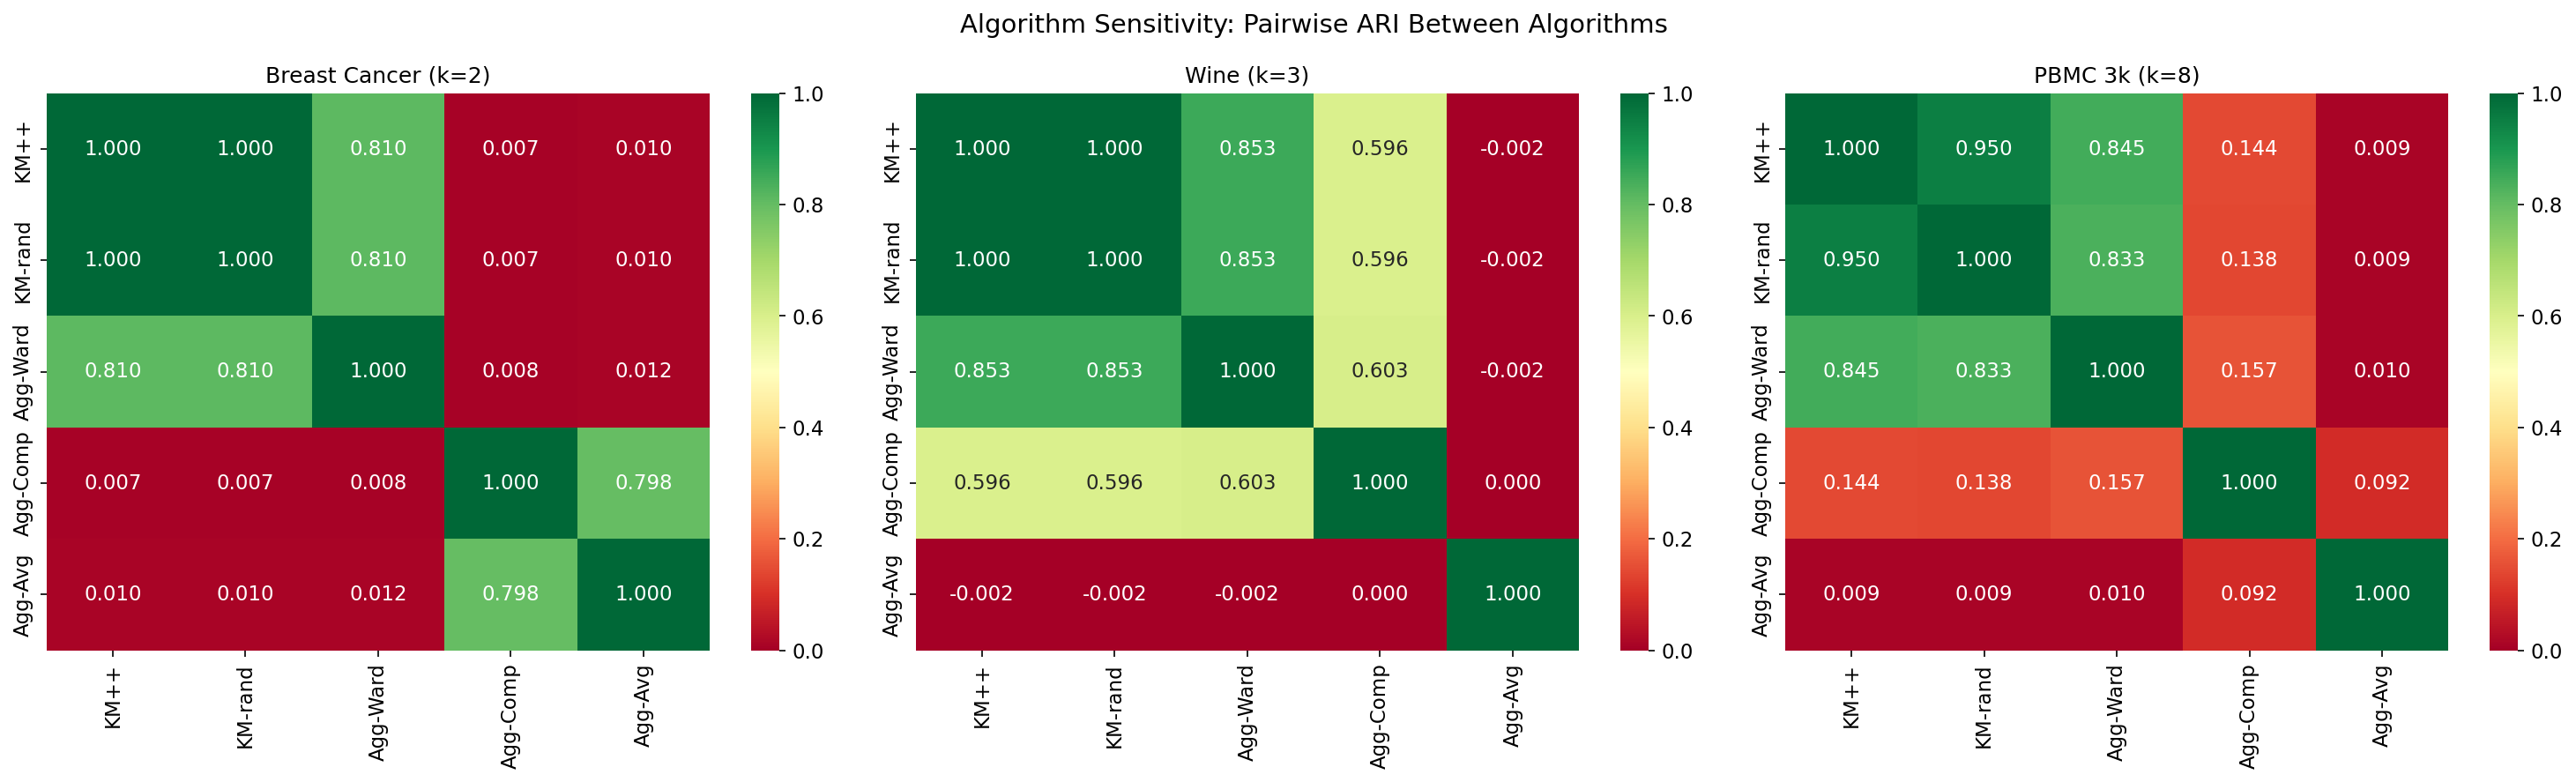

Figure saved: figures/12_algorithm_pairwise_ari_heatmaps.png


In [9]:
ALGORITHMS = {
    'KMeans (k-means++)': lambda k: KMeans(n_clusters=k, init='k-means++', random_state=RANDOM_STATE, n_init=10),
    'KMeans (random init)': lambda k: KMeans(n_clusters=k, init='random', random_state=RANDOM_STATE, n_init=10),
    'Agglomerative (ward)': lambda k: AgglomerativeClustering(n_clusters=k, linkage='ward'),
    'Agglomerative (complete)': lambda k: AgglomerativeClustering(n_clusters=k, linkage='complete'),
    'Agglomerative (average)': lambda k: AgglomerativeClustering(n_clusters=k, linkage='average'),
}

def algorithm_sensitivity(X_scaled, y_true, k, dataset_name):
    results = {}
    for name, algo_fn in ALGORITHMS.items():
        algo = algo_fn(k)
        labels = algo.fit_predict(X_scaled)
        results[name] = {'labels': labels, 'ari_vs_ground_truth': adjusted_rand_score(y_true, labels)}
        print(f"  {name}: ARI={results[name]['ari_vs_ground_truth']:.3f}")
    names = list(results.keys())
    pairwise = np.zeros((len(names), len(names)))
    for i, n1 in enumerate(names):
        for j, n2 in enumerate(names):
            pairwise[i, j] = adjusted_rand_score(results[n1]['labels'], results[n2]['labels'])
    return results, pairwise, names

print("Algorithm sensitivity: Breast Cancer...")
algo_bc, pairwise_algo_bc, algo_names = algorithm_sensitivity(X_bc_scaled, y_bc, k=2, dataset_name='Breast Cancer')
print("\nAlgorithm sensitivity: Wine...")
algo_wine, pairwise_algo_wine, _ = algorithm_sensitivity(X_wine_scaled, y_wine, k=3, dataset_name='Wine')
print("\nAlgorithm sensitivity: PBMC 3k...")
algo_pbmc, pairwise_algo_pbmc, _ = algorithm_sensitivity(X_pbmc_scaled, y_pbmc, k=8, dataset_name='PBMC 3k')

short_algo = ['KM++', 'KM-rand', 'Agg-Ward', 'Agg-Comp', 'Agg-Avg']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Algorithm Sensitivity: Pairwise ARI Between Algorithms', fontsize=14)

for ax, pairwise, title in [
    (axes[0], pairwise_algo_bc, 'Breast Cancer (k=2)'),
    (axes[1], pairwise_algo_wine, 'Wine (k=3)'),
    (axes[2], pairwise_algo_pbmc, 'PBMC 3k (k=8)'),
]:
    sns.heatmap(pairwise, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1,
                xticklabels=short_algo, yticklabels=short_algo, ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.savefig('figures/12_algorithm_pairwise_ari_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/12_algorithm_pairwise_ari_heatmaps.png")

## Summary of Results

### Interpreting the cross-experiment summary

The summary table and visualisations below aggregate results across all experiments. A few cross-cutting observations to guide interpretation:

**For Breast Cancer and Wine (independent ground truth):** ARI vs ground truth is a meaningful measure of whether clustering recovered real structure. Experiments where ARI drops substantially (more than 0.1 below baseline) indicate genuine sensitivity to that factor. Preprocessing sensitivity is expected to be high for these datasets because of raw feature scale differences.

**For PBMC 3k (Louvain-derived ground truth):** ARI vs ground truth measures inter-algorithm agreement. All conclusions about PBMC should be read as statements about the relationship between KMeans and Louvain, not about biological truth. Bootstrap stability for PBMC is more meaningful than ARI vs ground truth, because stability measures whether KMeans is finding consistent structure, regardless of what Louvain does.

**Violin plot interpretation:** The violin plot shows the distribution of ARI values across all methods within each experiment type and dataset. A narrow, high violin means the experiment type had little effect on ARI for that dataset (results were consistent regardless of method). A wide or bimodal violin means some methods gave very different results, indicating substantial sensitivity to that factor.

          Dataset     Experiment                           Method  ARI_vs_GT  Bootstrap_Stability      Notes
0   Breast Cancer       Baseline        KMeans+StandardScaler k=2   0.653625             0.950493  NMI=0.532
1            Wine       Baseline        KMeans+StandardScaler k=3   0.897495             0.964756  NMI=0.876
2         PBMC 3k       Baseline        KMeans+StandardScaler k=8   0.779062             0.765909  NMI=0.811
3   Breast Cancer  Preprocessing                 No scaling (raw)   0.491425                  NaN  Sil=0.697
4   Breast Cancer  Preprocessing         StandardScaler (z-score)   0.653625                  NaN  Sil=0.343
5   Breast Cancer  Preprocessing               MinMaxScaler [0,1]   0.730175                  NaN  Sil=0.385
6   Breast Cancer  Preprocessing               RobustScaler (IQR)   0.629146                  NaN  Sil=0.366
7            Wine  Preprocessing                 No scaling (raw)   0.371114                  NaN  Sil=0.571
8            Wine  

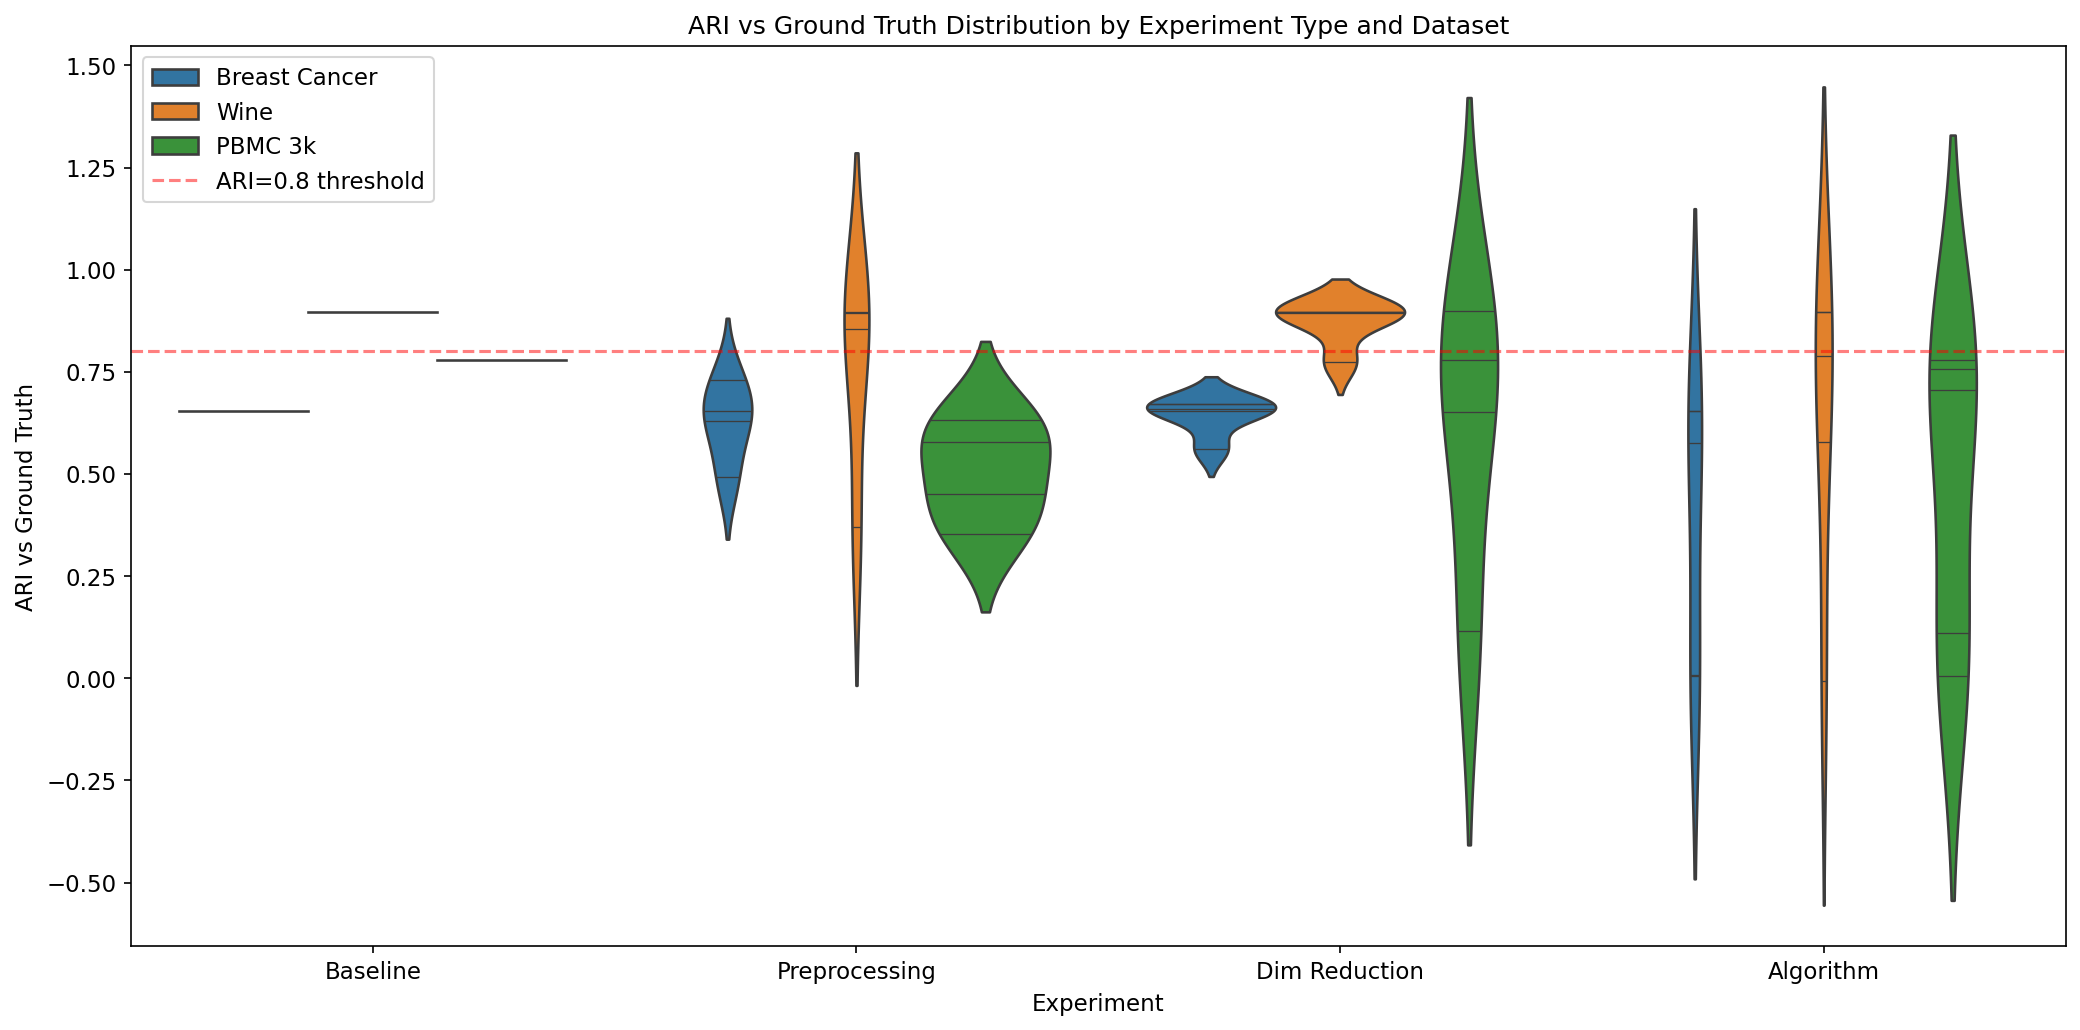

Figure saved: figures/13_summary_violin.png


In [10]:
summary = []

# Baselines
for name, baseline, stab, k in [
    ('Breast Cancer', baseline_bc, stab_bc, 2),
    ('Wine', baseline_wine, stab_wine, 3),
    ('PBMC 3k', baseline_pbmc, stab_pbmc, 8),
]:
    summary.append({'Dataset': name, 'Experiment': 'Baseline', 'Method': f'KMeans+StandardScaler k={k}',
                    'ARI_vs_GT': baseline['ari'], 'Bootstrap_Stability': stab['mean_ari'],
                    'Notes': f"NMI={baseline['nmi']:.3f}"})

# Preprocessing BC/Wine
for name, results, names in [
    ('Breast Cancer', results_prep_bc, scaler_names),
    ('Wine', results_prep_wine, scaler_names),
]:
    for n in names:
        summary.append({'Dataset': name, 'Experiment': 'Preprocessing', 'Method': n,
                        'ARI_vs_GT': results[n]['ari_vs_ground_truth'], 'Bootstrap_Stability': np.nan,
                        'Notes': f"Sil={results[n]['silhouette']:.3f}"})

# Preprocessing PBMC
for n in pbmc_pipeline_names:
    summary.append({'Dataset': 'PBMC 3k', 'Experiment': 'Preprocessing', 'Method': n,
                    'ARI_vs_GT': results_prep_pbmc[n]['ari_vs_ground_truth'], 'Bootstrap_Stability': np.nan,
                    'Notes': f"Sil={results_prep_pbmc[n]['silhouette']:.3f}"})

# Dim reduction BC/Wine
for ds_name, dimred_results in [('Breast Cancer', dimred_bc), ('Wine', dimred_wine), ('PBMC 3k', dimred_pbmc)]:
    for method, res in dimred_results.items():
        summary.append({'Dataset': ds_name, 'Experiment': 'Dim Reduction', 'Method': method,
                        'ARI_vs_GT': res['ari_vs_ground_truth'], 'Bootstrap_Stability': res['bootstrap_mean_ari'],
                        'Notes': f"dims={res['n_dims']}"})

# Algorithm
for ds_name, algo_results in [('Breast Cancer', algo_bc), ('Wine', algo_wine), ('PBMC 3k', algo_pbmc)]:
    for n in algo_names:
        summary.append({'Dataset': ds_name, 'Experiment': 'Algorithm', 'Method': n,
                        'ARI_vs_GT': algo_results[n]['ari_vs_ground_truth'], 'Bootstrap_Stability': np.nan, 'Notes': ''})

summary_df = pd.DataFrame(summary)
summary_df.to_csv('results_summary.csv', index=False)
print(summary_df.to_string())

# Violin plot
fig, ax = plt.subplots(figsize=(14, 7))
plot_data = []
for _, row in summary_df.iterrows():
    if not np.isnan(row['ARI_vs_GT']):
        plot_data.append({'Experiment': row['Experiment'], 'Dataset': row['Dataset'], 'ARI': row['ARI_vs_GT']})
plot_df = pd.DataFrame(plot_data)
sns.violinplot(data=plot_df, x='Experiment', y='ARI', hue='Dataset', ax=ax, inner='stick')
ax.set_title('ARI vs Ground Truth Distribution by Experiment Type and Dataset')
ax.set_xlabel('Experiment'); ax.set_ylabel('ARI vs Ground Truth')
ax.axhline(0.8, color='red', linestyle='--', alpha=0.5, label='ARI=0.8 threshold')
ax.legend()
plt.tight_layout()
plt.savefig('figures/13_summary_violin.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figures/13_summary_violin.png")

In [11]:
results_json = {
    'breast_cancer': {
        'baseline_ari': baseline_bc['ari'],
        'baseline_silhouette': baseline_bc['silhouette'],
        'baseline_nmi': baseline_bc['nmi'],
        'bootstrap_mean_ari_standard': stab_bc['mean_ari'],
        'bootstrap_std_ari_standard': stab_bc['std_ari'],
        'best_scaler_ari': max(results_prep_bc[n]['ari_vs_ground_truth'] for n in scaler_names),
        'worst_scaler_ari': min(results_prep_bc[n]['ari_vs_ground_truth'] for n in scaler_names),
        'preprocessing_ari_range': max(results_prep_bc[n]['ari_vs_ground_truth'] for n in scaler_names) - min(results_prep_bc[n]['ari_vs_ground_truth'] for n in scaler_names),
        'min_pairwise_scaler_ari': float(pairwise_bc[np.tril_indices_from(pairwise_bc, k=-1)].min()),
    },
    'wine': {
        'baseline_ari': baseline_wine['ari'],
        'baseline_silhouette': baseline_wine['silhouette'],
        'baseline_nmi': baseline_wine['nmi'],
        'bootstrap_mean_ari_standard': stab_wine['mean_ari'],
        'bootstrap_std_ari_standard': stab_wine['std_ari'],
        'best_scaler_ari': max(results_prep_wine[n]['ari_vs_ground_truth'] for n in scaler_names),
        'worst_scaler_ari': min(results_prep_wine[n]['ari_vs_ground_truth'] for n in scaler_names),
        'preprocessing_ari_range': max(results_prep_wine[n]['ari_vs_ground_truth'] for n in scaler_names) - min(results_prep_wine[n]['ari_vs_ground_truth'] for n in scaler_names),
        'min_pairwise_scaler_ari': float(pairwise_wine[np.tril_indices_from(pairwise_wine, k=-1)].min()),
    },
    'pbmc_3k': {
        'baseline_ari': baseline_pbmc['ari'],
        'baseline_silhouette': baseline_pbmc['silhouette'],
        'baseline_nmi': baseline_pbmc['nmi'],
        'bootstrap_mean_ari_standard': stab_pbmc['mean_ari'],
        'bootstrap_std_ari_standard': stab_pbmc['std_ari'],
        'best_pipeline_ari': max(results_prep_pbmc[n]['ari_vs_ground_truth'] for n in pbmc_pipeline_names),
        'worst_pipeline_ari': min(results_prep_pbmc[n]['ari_vs_ground_truth'] for n in pbmc_pipeline_names),
        'preprocessing_ari_range': max(results_prep_pbmc[n]['ari_vs_ground_truth'] for n in pbmc_pipeline_names) - min(results_prep_pbmc[n]['ari_vs_ground_truth'] for n in pbmc_pipeline_names),
        'min_pairwise_pipeline_ari': float(pairwise_pbmc[np.tril_indices_from(pairwise_pbmc, k=-1)].min()),
        'ground_truth_note': 'Louvain-derived cell type annotations. Not an independent label set.',
    }
}

with open('results.json', 'w') as f:
    json.dump(results_json, f, indent=2)
print("Results saved to results.json")
print(json.dumps(results_json, indent=2))

Results saved to results.json
{
  "breast_cancer": {
    "baseline_ari": 0.6536246043910179,
    "baseline_silhouette": 0.34338224069077816,
    "baseline_nmi": 0.5324078598532422,
    "bootstrap_mean_ari_standard": 0.9504928872842793,
    "bootstrap_std_ari_standard": 0.04599243978764493,
    "best_scaler_ari": 0.7301749027614344,
    "worst_scaler_ari": 0.49142453622455523,
    "preprocessing_ari_range": 0.23875036653687914,
    "min_pairwise_scaler_ari": 0.49623538611502815
  },
  "wine": {
    "baseline_ari": 0.8974949815093207,
    "baseline_silhouette": 0.2848589191898987,
    "baseline_nmi": 0.8758935341223069,
    "bootstrap_mean_ari_standard": 0.9647555813706747,
    "bootstrap_std_ari_standard": 0.04231735272800692,
    "best_scaler_ari": 0.8974949815093207,
    "worst_scaler_ari": 0.37111371823084754,
    "preprocessing_ari_range": 0.5263812632784732,
    "min_pairwise_scaler_ari": 0.3543189207971098
  },
  "pbmc_3k": {
    "baseline_ari": 0.779062290059806,
    "baseline_si

## Limitations

This section states explicitly what this analysis can and cannot conclude. Limitations are not caveats to be buried; they define the scope of valid inference.

**1. Only KMeans and agglomerative clustering are evaluated.** Density-based methods (DBSCAN, HDBSCAN), graph-based methods (Louvain, Leiden), and mixture model methods (Gaussian Mixture Models) are not included. Conclusions about "clustering stability" apply specifically to the algorithms tested. DBSCAN, for example, can find non-spherical clusters and identifies outliers as noise; its stability profile under the same perturbations could be qualitatively different.

**2. Only Euclidean distance is used.** KMeans and Ward agglomerative clustering both use Euclidean distance implicitly. Other distance metrics (cosine similarity, correlation distance, Manhattan distance) can produce substantially different cluster assignments on the same data, particularly in high-dimensional spaces where Euclidean distance degrades. The experiments do not probe metric sensitivity.

**3. Bootstrap stability measures sensitivity to sample inclusion, not to feature noise.** The perturbation tested is: what happens if 20% of samples are removed? This is different from: what happens if measurement noise is added to feature values? The latter (feature perturbation) is arguably more relevant for experimental data where measurements have known noise levels. The two types of stability can give different answers.

**4. The sklearn datasets are well-separated benchmarks.** Breast Cancer and Wine are standard machine learning benchmarks chosen partly because clustering works well on them. Results from these datasets cannot be generalised to say that clustering is reliable in general. They establish best-case performance under favourable conditions.

**5. PCA before KMeans is not equivalent to PCA before UMAP before KMeans.** The dimensionality reduction experiments test several pipelines but do not test all combinations. In practice, the order of operations (PCA then cluster vs PCA then UMAP then cluster) can matter, and this analysis does not fully characterise the interaction between dimensionality reduction and clustering.

**6. n_init=10 for KMeans is a practical choice, not a guarantee of global optimum.** KMeans is run 10 times with different initialisations and the best result is kept. This reduces but does not eliminate sensitivity to initialisation. For some datasets, n_init=10 may be insufficient. The bootstrap stability experiments partially capture this because each bootstrap run uses a different random seed.

**7. UMAP hyperparameters are left at defaults (n_neighbors=15, min_dist=0.1).** UMAP is known to be sensitive to these parameters. Different choices can produce qualitatively different layouts, which will affect KMeans applied to the UMAP coordinates. The UMAP results should be treated as indicative rather than definitive.

**8. The PBMC ground truth is circular.** The cell type labels in `adata.obs['louvain']` were produced by running the Louvain community detection algorithm on the PBMC data, then manually annotating the resulting clusters by inspecting marker gene expression. These labels were not determined by an independent assay (such as FACS sorting or single-cell proteomics). Measuring ARI between KMeans and Louvain labels is measuring agreement between two clustering algorithms. It is not measuring recovery of biological truth. A high ARI does not mean the clusters are biologically correct; it means KMeans partitions the data similarly to how Louvain partitioned it. A low ARI might mean KMeans finds a different partition of the cells, which could be more, less, or equally biologically meaningful depending on the scientific question.

**9. The PBMC preprocessing pipeline used here is the scanpy tutorial default.** The preprocessing comparison in this notebook (raw counts vs normalised vs normalised plus log vs full pipeline) only scratches the surface of the full decision space for single-cell RNA-seq analysis. Other choices include: which highly variable gene selection method to use, how many HVGs to retain, whether to regress out confounders (cell cycle phase, mitochondrial fraction), which PCA implementation to use, and how many principal components to retain. Each of these choices can affect downstream clustering. The scanpy tutorial pipeline is a reasonable and widely used starting point, but it is not the only valid approach, and the sensitivity of PBMC clustering conclusions to the full preprocessing decision space is substantially larger than what is shown here.